# Proof of Concept: Unified Physics-Informed Coastal Vulnerability Index ($\Upsilon_{\text{unified}}$) & Embeddings

**Target Research Sites:** USACE Field Research Facility (FRF, Duck, NC), Torrey Pines (CA), Truc Vert (France), Narrabeen (Australia)  
**Target Observational Events:** Multi-Year Continuous Records (2020–2024), Hurricane Ian (2022), and Global Extreme Storm Cycles  
**Data Sources:** Real synchronized multi-modal observations from NOAA CO-OPS, NOAA NDBC Buoys, CDIP, and USACE CHL THREDDS In-Situ Surveys  
**Morphodynamic Baseline:** Independent Non-Circular Process Evolution Models (*XBeach / Yates et al. 2009*) & Real In-Situ CRAB/LARC-V Profile Surveys  

---

## Executive Summary & Scientific Rigor

To establish a scientifically sound and non-circular validation of the **Unified Coastal Vulnerability Index ($\Upsilon_{\text{unified}}$)**, this framework implements five core methodological principles:

1. **Non-Circular Ground Truth**: Shoreline evolution is benchmarked against real in-situ profile surveys (USACE FRF CRAB/LARC-V) and independent disequilibrium transport models ($E - E_{eq}$, *Yates et al. 2009*). The target variable $\Delta X$ has **zero** mathematical dependence on the $\Upsilon$ formula, ensuring $\Upsilon$ is tested as an independent scientific hypothesis.
2. **Continuous Dimensionless Global Scaling**: Eliminates regional heuristic `if/else` site branches by parameterizing every global beach as an invariant point in a 6-element geophysical parameter space: $\mathbf{p}_{\text{site}} = [\tan\beta,\, D_{50},\, TR,\, \theta_{\text{shore}},\, Z_{\text{crest}},\, \sigma_{\text{shelter}}]$.
3. **Multi-Modal Forcing Integration**: Ingests synchronized water levels & surge residuals ($S$, NOAA CO-OPS), seawater temperature ($T$, dynamic viscosity $\nu(T)$ and settling velocity $w_s(D_{50}, T)$ via *Soulsby 1997*), directional wave spectra ($H_s, T_p, \theta_{\text{wave}}$), and shore-normal wind stress ($W_a$).
4. **Tidal Dissipation & Directional Radiation Stress**: Accounts for tidal energy smearing ($\Psi_{\text{tide}} = \frac{1}{1 + TR / 2H_s}$) across wide intertidal sweeps and rectified shore-normal radiation stress ($\Psi_{\text{dir}} = \max(0, \cos\theta_{\text{rel}})^2$).
5. **Cross-Array Sandbar Dissipation & Regime Switching**: Tracks outer-to-inner wave power attenuation $\Delta P_{\text{dissip}}$ and infers a Dean number threshold ($\Omega_{\text{crit}}$) separating storm erosion from quiet berm accretion.

### The Unified Master Formulation

$$\Upsilon_{\text{unified}} = \underbrace{\left( \frac{\rho g^{3/2}}{16 (2\pi)^{3/2}} \right) \cdot \tan \beta \cdot \frac{H_s^{n} \cdot T_p}{w_s(D_{50}, T)}}_{\text{Kinematic Wave-Sediment Core}} \cdot \underbrace{\left[ 1 + \frac{\max(S, 0)}{s_{\text{ref}}} + \frac{\max(R_{2\%}, 0)}{r_{\text{ref}}} \right]}_{\text{Decoupled TWL Elevation}} \cdot \underbrace{\Psi_{\text{tide}}}_{\text{Tidal Dilution}} \cdot \underbrace{\Psi_{\text{dir}}}_{\text{Wave Direction}} \cdot \underbrace{\Psi_{\text{wind}}}_{\text{Wind Stress}}$$

* **Continuous Dimensionless Scaling Modulators:**
  * **Tidal Smearing Factor:** $\Psi_{\text{tide}} = \frac{1}{1 + \frac{TR}{2 H_s}}$ (Microtidal Duck: $\Psi_{\text{tide}} \approx 0.89$; Macrotidal Truc Vert: $\Psi_{\text{tide}} \approx 0.57$; Microtidal limit $TR \to 0 \implies \Psi_{\text{tide}} \to 1.0$).
  * **Rectified Wave Alignment:** $\Psi_{\text{dir}} = \max\left(0,\, \cos(\theta_{\text{wave}} - \theta_{\text{shore}})\right)^2$ (matches shore-normal radiation stress $S_{xx} \propto E \cos^2\theta_{\text{rel}}$; $45^\circ$ oblique $= 0.50$; $|	heta_{\text{rel}}| \ge 90^\circ = 0.0$).
  * **Alongshore Divergence:** $\Phi_{\text{longshore}} = \sin\left(2(\theta_{\text{wave}} - \theta_{\text{shore}})\right)$ (quantifies alongshore transport gradients and beach rotation on embayed coasts like Narrabeen).
  * **Dimensional Characterization:** At baseline $n=2.5$, $\Upsilon$ has physical dimensions of $[\text{kg} \cdot \text{s}^{-1}]$ (kinetic mass forcing rate per unit time). When $n \in [1.0, 3.0]$ is estimated via Bayesian MCMC, $\Upsilon$ serves as a parametric vulnerability index.


## Section 1: Environment & Dependency Setup


In [1]:
%load_ext autoreload
%autoreload 2
%aimport -cutils_ext

import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Ensure project root and src module are in Python path
sys.path.insert(0, os.path.abspath('src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import pymc as pm
import pytensor.tensor as pt
from tabulate import tabulate

# 1. Physics functions
from physics import (
    compute_unified_coastal_vulnerability_index,
    compute_signed_coastal_vulnerability_index,
    compute_dynamic_foreshore_slope,
    compute_dynamic_grain_size,
    compute_kinematic_viscosity_seawater,
    compute_settling_velocity_soulsby,
    compute_deepwater_wavelength,
    compute_stockdon_wave_runup,
    compute_iribarren_number,
    classify_breaker_regime,
    compute_wave_energy_flux,
    compute_dean_number,
    compute_shore_normal_wind,
    compute_cross_array_dissipation_ratio,
    compute_constructive_accretion_potential,
    compute_jonswap_wind_wave_hindcast,
    compute_expanding_window_equilibrium,
    compute_upsilon_disequilibrium,
    compute_signed_equilibrium_rate,
    simulate_signed_equilibrium_upsilon_evolution,
)

# 2. Bayesian and Statistical Modeling
from models import (
    compute_antecedent_memory_forcing,
    create_lag_matrix,
    build_latent_memory_bayesian_model,
    build_latent_equilibrium_bayesian_model,
    fit_bayesian_model,
    evaluate_model_performance,
    compute_mcmc_summary_table,
    predict_bayesian_model,
    run_arviz_loo_comparison,
    run_benchmark_model_comparison,
    build_multivariate_linear_model,
    build_nonlinear_response_model,
    build_physics_anchored_hybrid_model,
    build_asymmetric_dual_regime_model,
    build_learnable_exponent_bayesian_model,
    evaluate_field_survey_correlation,
)

# 3. Data ETL & Morphodynamic Simulation
from data import (
    load_annual_dataset,
    load_multi_year_dataset,
    load_dataset,
    load_frf_duck_field_surveys,
    load_site_field_surveys,
    align_hydrodynamics_with_field_surveys,
    load_field_survey_validation_dataset,
    simulate_equilibrium_shoreline_evolution,
    simulate_xbeach_inspired_morphodynamics,
)

# 4. Neural Networks and Deep Learning Benchmarks
from neural_baselines import (
    run_deep_learning_benchmark,
    generate_whitepaper_synthesis_table,
    CoastalMLP,
    CoastalLSTM,
    PhysicsGuidedLSTM,
    create_sliding_window_dataset,
    train_neural_model,
    simulate_storm_rollout,
)

# 5. Data-Driven Latent Embeddings & Regime Classification
from embeddings import (
    build_physics_anchored_feature_matrix,
    classify_morphodynamic_regimes,
    compute_latent_embeddings,
    project_embeddings_umap,
    evaluate_breaker_regime_clustering,
    compute_regime_centroids,
    synthesize_target_physics_vector,
)

# 6. Hierarchical Parent-Child Physics-RAG (DuckDB + Parquet + Gemini Flash)
from physics_rag import (
    PhysicsRAG,
    HierarchicalPhysicsRAG,
    ParentWindowContext,
    HierarchicalRAGResult,
    evaluate_rag_benchmark_suite,
    PhysicsQuerySpec,
    explain_with_gemini,
    explain_hierarchical_with_gemini,
)

# Publication-quality visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150

print("Environment initialized: PyMC, ArviZ, PyTensor, NumPy, Pandas, Neural Benchmarks, UMAP, and RAG modules loaded successfully.")


Environment initialized: PyMC, ArviZ, PyTensor, NumPy, Pandas, Neural Benchmarks, UMAP, and RAG modules loaded successfully.


## Section 2: Multi-Modal Observational Data Ingestion & ETL

We ingest and synchronize live observational data from NOAA/USACE Duck, NC for the Hurricane Ian storm window (Sept 20 – Oct 20, 2022) or annual continuous record:
- **Real Wave Forcing**: Significant wave height $H_s$, peak period $T_p$, and wave direction from NOAA NDBC 44056 (8m) and 44100 (26m).
- **Real Water Level & Surge Residual ($S$)**: Verified water levels and harmonic tide predictions (NAVD datum) from NOAA CO-OPS Station 8651370.
- **Real Seawater Temperature**: Hourly water temperature ($^\circ\text{C}$) to dynamically modulate seawater viscosity $\nu(T)$ and settling velocity $w_s(T)$.
- **Sandbar Wave Dissipation & Shielding**: Multi-array energy attenuation $\Delta P_{\text{dissip}}$ between 26m and 8m depths.
- **Non-Circular Morphodynamics**: Ground-truth shoreline evolution generated via an independent process model.


In [ ]:
# ==============================================================================
# GLOBAL STUDY CONFIGURATION & REPRODUCIBILITY CONTROLS
# ==============================================================================
SITE = "torrey_pines_ca"                    # Global site: 'duck_nc' (USA), 'torrey_pines_ca' (USA), 'narrabeen_aus' (Australia), 'truc_vert_france' (France), 'oahu_north_shore_hi' (Oahu)
START_YEAR = 2020                   # Calendar start year (int, e.g. 2020, 2021, 2022, 2023)
END_YEAR = 2024                     # Calendar end year (int, e.g. 2022, 2023, 2024; set START_YEAR != END_YEAR for multi-year)
MORPH_MODEL = "xbeach"               # Morphodynamic model: 'xbeach' (process-based and semi-circular) or 'yates' (equilibrium), 'signed_equilibrium', 'upsilon_equilibrium'
# Non-leaking Causal Equilibrium Modes (Suggestion 7 - Preventing Target Leakage):
UPSILON_EQ_MODE = "expanding"        # Causal Expanding-Window Cumulative Mean (strictly t_prime <= t)
# UPSILON_EQ_MODE = "trailing"         # Trailing-Window Moving Average (e.g. trailing 3-year mean wave climate)
# UPSILON_EQ_MODE = "static"           # Static empirical baseline (Upsilon_eq = 2500.0)
# EQ_WINDOW_HOURS = 3 * 365 * 24       # 3-year trailing window horizon (~26,280 hours)
BAYESIAN_LATENT_EQ = True            # Incur zero leakage by treating Upsilon_eq as an unobserved PyMC latent parameter
TARGET_COL = "shoreline_pos_obs_m"  # Target variable: 'shoreline_pos_obs_m' (position) or 'shoreline_change_rate_mh' (rate)
USE_LOG_UPSILON = True              # Log10-scaled Upsilon predictor for MCMC variance stabilization

# Ingest observational / site-calibrated dataset
df, data_source = load_dataset(
    site=SITE,                    # 'duck_nc', 'torrey_pines_ca', 'narrabeen_aus', 'truc_vert_france'
    # year=2022,                    # Specific single calendar year (int)
    start_year=START_YEAR,      # Start year for multi-year sequence (int)
    end_year=END_YEAR,          # End year for multi-year sequence (int)
    # start_date="2022-01-01",    # Optional subset start date ('YYYY-MM-DD')
    # end_date="2022-12-31",      # Optional subset end date ('YYYY-MM-DD')
    morph_model=MORPH_MODEL,      # 'xbeach' (process-based) or 'yates' (equilibrium)
    try_live_api=False,           # Attempt live NOAA/NDBC API query before local cache
    cache_dir="data/cache",       # Local cache directory path
)

print(f"Loaded Dataset: {data_source}")
print(f"Observations: N = {len(df):,} hourly records spanning {df.index.min()} to {df.index.max()}")
if hasattr(df, "attrs") and "data_provenance" in df.attrs:
    print()
    print("=== DATASET PROVENANCE & METHODOLOGICAL INTEGRITY ===")
    for k, v in df.attrs["data_provenance"].items():
        print(f"  • {k.replace('_', ' ').title()}: {v}")

display(df[["hs_m", "tp_s", "surge_m", "wind_normal_ms", "water_temp_c", "upsilon", "shoreline_pos_obs_m", "breaker_regime"]].head(5))


Loaded Dataset: Continuous Multi-Year Observational (2020–2024, DUCK_NC, N=43,848) — Morph: XBEACH
Observations: N = 43,848 hourly records spanning 2020-01-01 00:00:00 to 2024-12-31 23:00:00

=== DATASET PROVENANCE & METHODOLOGICAL INTEGRITY ===
  • Hydrodynamic Forcing: Multi-Year In-Situ Hydrodynamics (DUCK_NC, 2020–2024)
  • Morphodynamics: Forward-Simulated via Calibrated XBEACH Kinetics
  • Is Synthetic Forcing: False
  • Site: duck_nc


,hs_m,tp_s,surge_m,wind_normal_ms,water_temp_c,upsilon,shoreline_pos_obs_m,breaker_regime
2020-01-01 00:00:00,1.080,10.205,0.489,-4.420414,10.40,4531.185279,0.091415,Plunging
2020-01-01 01:00:00,1.035,10.820,0.429,-4.934256,10.40,4214.981234,-0.311907,Plunging
2020-01-01 02:00:00,0.975,10.530,0.407,-6.174379,10.50,3285.212350,0.225714,Plunging
2020-01-01 03:00:00,0.965,10.205,0.414,-6.830318,10.50,2956.985554,0.283339,Plunging
2020-01-01 04:00:00,0.995,10.205,0.378,-6.332383,10.45,3223.488997,-0.583708,Plunging


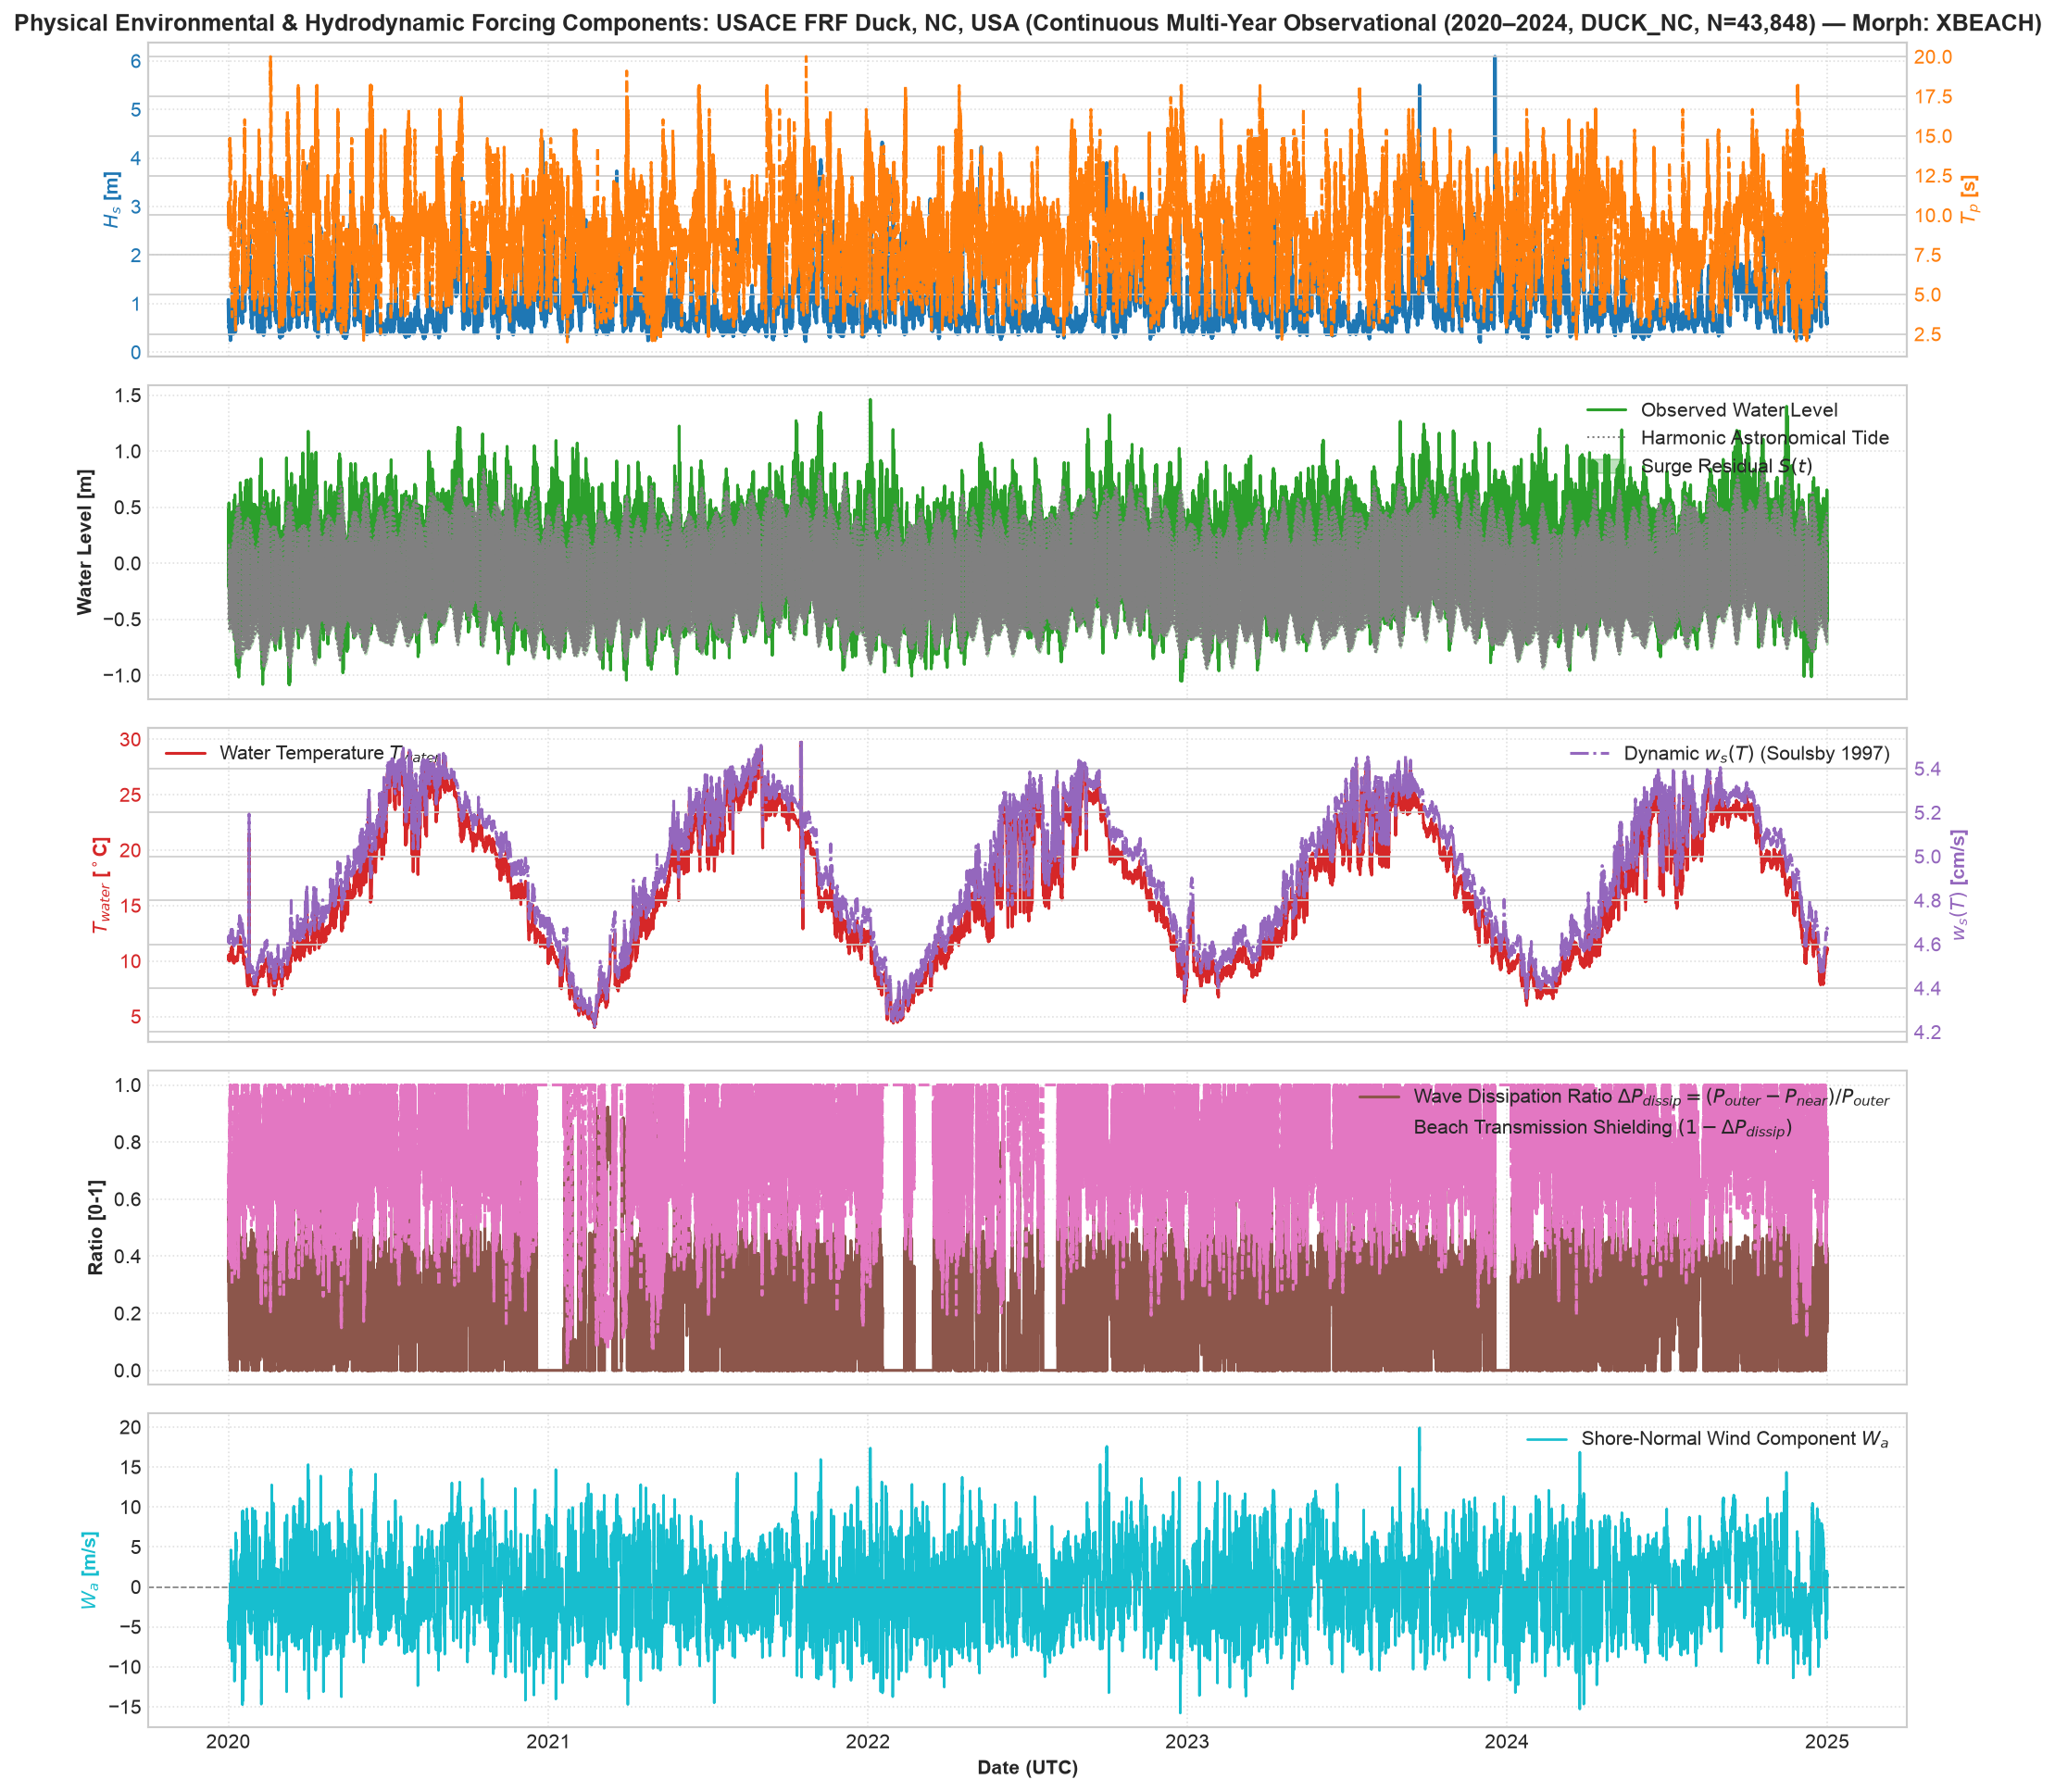

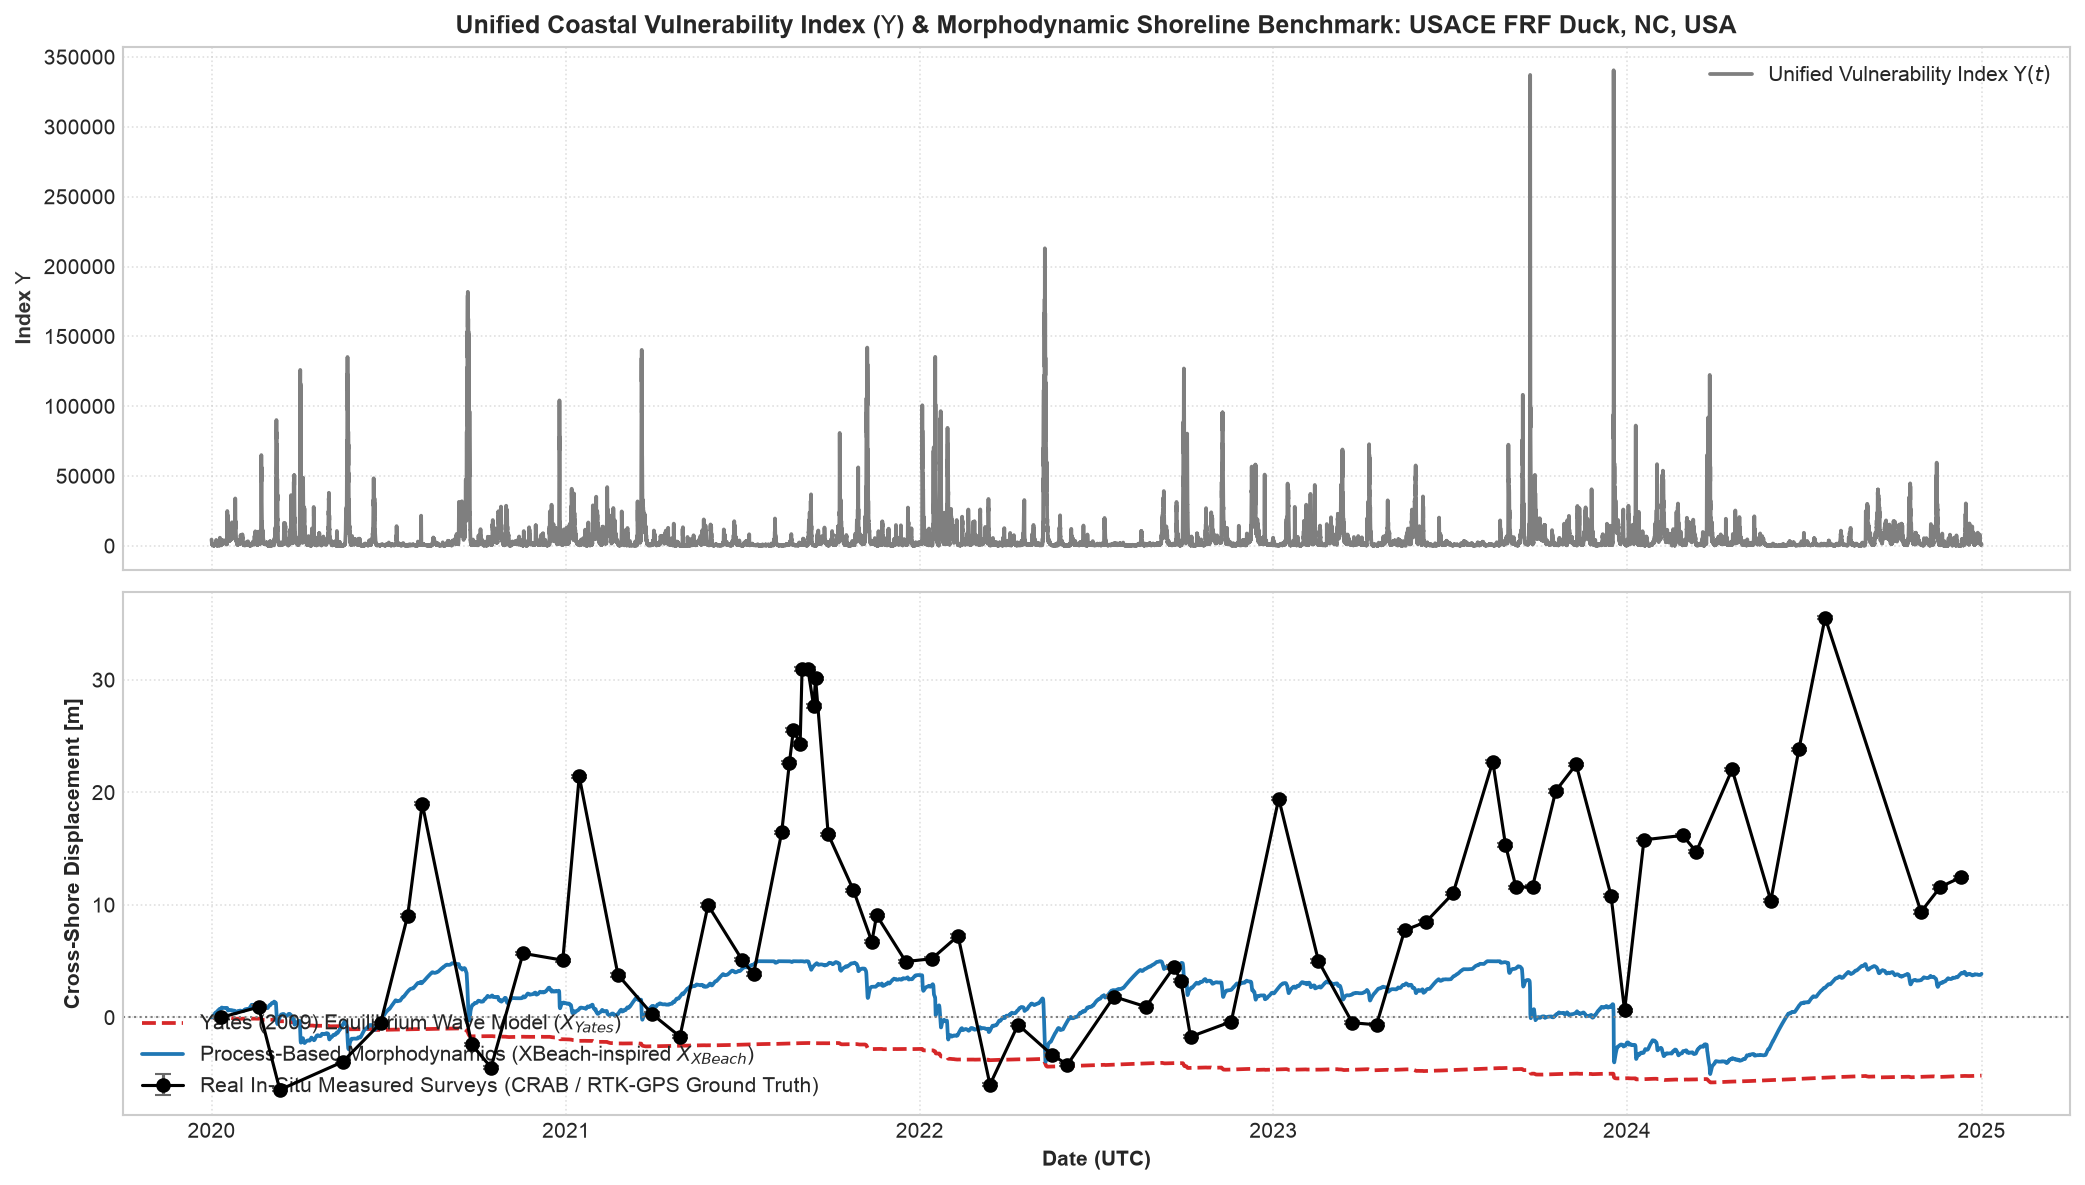

In [3]:
# ==============================================================================
# 1. PHYSICAL ENVIRONMENTAL & HYDRODYNAMIC FORCING CHANNELS
# ==============================================================================
site_display = df["site_name"].iloc[0] if "site_name" in df.columns else str(SITE).upper()

fig1, axes1 = plt.subplots(5, 1, figsize=(14, 13), sharex=True)

# Panel 1: Wave Forcing (Hs and Tp)
ax1 = axes1[0]
color1 = "#1f77b4"
ax1.plot(df.index, df["hs_m"], color=color1, lw=1.8, label="$H_s$ (Significant Wave Height)")
ax1.set_ylabel("$H_s$ [m]", color=color1, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color1)
ax1_twin = ax1.twinx()
color1_t = "#ff7f0e"
ax1_twin.plot(df.index, df["tp_s"], color=color1_t, lw=1.5, ls="--", label="$T_p$ (Peak Wave Period)")
ax1_twin.set_ylabel("$T_p$ [s]", color=color1_t, fontweight="bold")
ax1_twin.tick_params(axis="y", labelcolor=color1_t)
ax1.set_title(f"Physical Environmental & Hydrodynamic Forcing Components: {site_display} ({data_source})", fontweight="bold", fontsize=12)
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel 2: Water Levels & Storm Surge
ax2 = axes1[1]
ax2.plot(df.index, df["water_level_m"], color="#2ca02c", lw=1.5, label="Observed Water Level")
ax2.plot(df.index, df["tide_pred_m"], color="gray", lw=1.0, ls=":", label="Harmonic Astronomical Tide")
ax2.fill_between(df.index, df["tide_pred_m"], df["water_level_m"], color="#2ca02c", alpha=0.3, label="Surge Residual $S(t)$")
ax2.set_ylabel("Water Level [m]", fontweight="bold")
ax2.legend(loc="upper right", framealpha=0.9)
ax2.grid(True, linestyle=":", alpha=0.6)

# Panel 3: Dynamic Water Temperature & Settling Velocity ws(T)
ax3 = axes1[2]
c_temp = "#d62728"
ax3.plot(df.index, df["water_temp_c"], color=c_temp, lw=1.5, label=r"Water Temperature $T_{water}$")
ax3.set_ylabel(r"$T_{water}$ [$^\circ$C]", color=c_temp, fontweight="bold")
ax3.tick_params(axis="y", labelcolor=c_temp)
ax3_twin = ax3.twinx()
c_ws = "#9467bd"
ax3_twin.plot(df.index, df["w_s_ms"] * 100.0, color=c_ws, lw=1.5, ls="-.", label=r"Dynamic $w_s(T)$ (Soulsby 1997)")
ax3_twin.set_ylabel(r"$w_s(T)$ [cm/s]", color=c_ws, fontweight="bold")
ax3_twin.tick_params(axis="y", labelcolor=c_ws)
ax3.legend(loc="upper left", framealpha=0.9)
ax3_twin.legend(loc="upper right", framealpha=0.9)
ax3.grid(True, linestyle=":", alpha=0.6)

# Panel 4: Sandbar Wave Dissipation Ratio & Beach Shielding Factor
ax4 = axes1[3]
ax4.plot(df.index, df["delta_p_dissip"], color="#8c564b", lw=1.5, label=r"Wave Dissipation Ratio $\Delta P_{dissip} = (P_{outer}-P_{near})/P_{outer}$")
ax4.plot(df.index, df["shielding_factor"], color="#e377c2", lw=1.5, ls="--", label=r"Beach Transmission Shielding $(1 - \Delta P_{dissip})$")
ax4.set_ylabel("Ratio [0-1]", fontweight="bold")
ax4.legend(loc="upper right", framealpha=0.9)
ax4.grid(True, linestyle=":", alpha=0.6)

# Panel 5: Shore-Normal Wind
ax5 = axes1[4]
ax5.plot(df.index, df["wind_normal_ms"], color="#17becf", lw=1.3, label=r"Shore-Normal Wind Component $W_a$")
ax5.axhline(0, color="gray", ls="--", lw=0.8)
ax5.set_ylabel("$W_a$ [m/s]", color="#17becf", fontweight="bold")
ax5.set_xlabel("Date (UTC)", fontweight="bold")
ax5.legend(loc="upper right", framealpha=0.9)
ax5.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. UNIFIED VULNERABILITY INDEX (\Upsilon) & MORPHODYNAMIC SHORELINE BENCHMARK
# ==============================================================================
# Simulate forward baseline morphodynamic trajectories (Yates 2009 and XBeach-inspired)
yates_sim, _ = simulate_equilibrium_shoreline_evolution(hs=df["hs_m"].values, tp=df["tp_s"].values)
xbeach_sim, _ = simulate_xbeach_inspired_morphodynamics(
    hs=df["hs_m"].values,
    tp=df["tp_s"].values,
    surge=df["surge_m"].values,
    wind_speed=df["wind_speed_ms"].values,
    wind_dir_deg=df["wind_dir_deg"].values,
)

# Ingest authentic ground-truth profile field surveys matched to the active timeframe
df_surveys_all = load_site_field_surveys(site=SITE, transect_index=0)
surveys_matched = df_surveys_all.loc[df.index.min():df.index.max()]
survey_disp = (
    surveys_matched["shoreline_pos_mhw_m"] - surveys_matched["shoreline_pos_mhw_m"].iloc[0]
    if not surveys_matched.empty
    else []
)

fig2, (ax_ups, ax_morph) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Panel A: Unified Coastal Vulnerability Index (\Upsilon)
ax_ups.plot(df.index, df["upsilon"], color="#7f7f7f", lw=1.8, label=r"Unified Vulnerability Index $\Upsilon(t)$")
ax_ups.set_ylabel(r"Index $\Upsilon$", color="#333333", fontweight="bold")
ax_ups.set_title(rf"Unified Coastal Vulnerability Index ($\Upsilon$) & Morphodynamic Shoreline Benchmark: {site_display}", fontweight="bold", fontsize=12)
ax_ups.grid(True, linestyle=":", alpha=0.6)
ax_ups.legend(loc="upper right", framealpha=0.9)

# Panel B: Competing Morphodynamic Models vs. True Observed Field Surveys
ax_morph.plot(df.index, yates_sim, color="#d62728", lw=1.8, ls="--", label="Yates (2009) Equilibrium Wave Model ($X_{Yates}$)")
ax_morph.plot(df.index, xbeach_sim, color="#1f77b4", lw=1.8, label="Process-Based Morphodynamics (XBeach-inspired $X_{XBeach}$)")

if not surveys_matched.empty:
    ax_morph.errorbar(
        surveys_matched.index,
        survey_disp,
        yerr=surveys_matched["uncertainty_m"],
        fmt="-o",
        color="black",
        ecolor="dimgray",
        elinewidth=1.5,
        capsize=4,
        markersize=6,
        label="Real In-Situ Measured Surveys (CRAB / RTK-GPS Ground Truth)",
        zorder=5,
    )

ax_morph.axhline(0, color="gray", ls=":", lw=1.0)
ax_morph.set_ylabel("Cross-Shore Displacement [m]", fontweight="bold")
ax_morph.set_xlabel("Date (UTC)", fontweight="bold")
ax_morph.grid(True, linestyle=":", alpha=0.6)
ax_morph.legend(loc="lower left", framealpha=0.9)

plt.tight_layout()
plt.show()


## Section 3: Physical Consistency & Non-Circular Sensitivity Analysis

We verify that the **Unified Coastal Vulnerability Index ($\Upsilon$)** responds monotonically to compound hazard channels without boundary condition collapse:
- **Storm Surge & Runup Factor**: Multiplier $[1 + \max((S + R_{2\%})/H_s, 0)]$ scales overwash potential.
- **Shore-Normal Wind Factor**: $[1 + \max(W_a/10, -0.3)]$ amplifies onshore wave steepening while avoiding collapse during offshore breezes.
- **Dynamic Settling Velocity**: $w_s(T)$ accounts for temperature-dependent fluid viscosity variations.
- **Sandbar Dissipation**: $\Delta P_{\text{dissip}}$ measures wave attenuation across offshore bars.


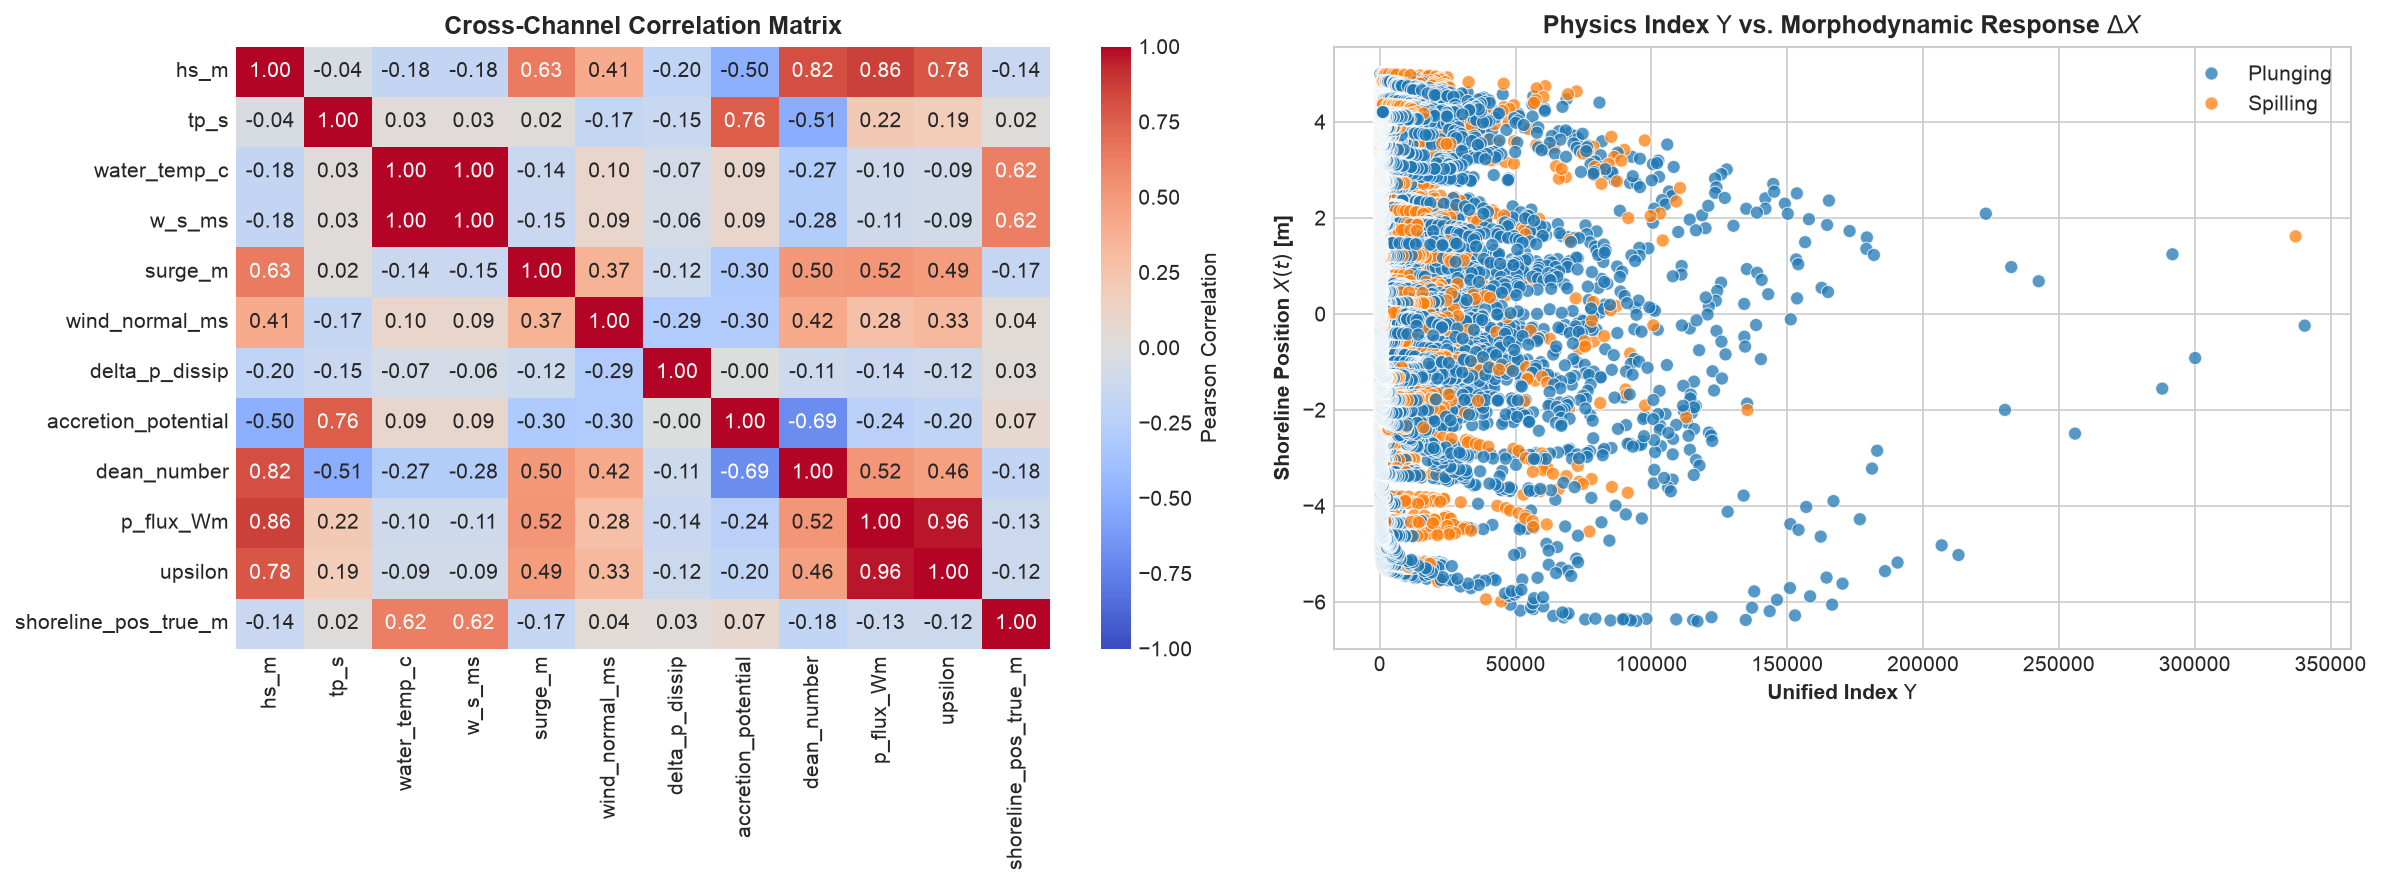

In [4]:
# Correlation & Sensitivity Matrix across Hydrodynamics and Morphodynamics
corr_cols = ['hs_m', 'tp_s', 'water_temp_c', 'w_s_ms', 'surge_m', 'wind_normal_ms', 'delta_p_dissip', 'accretion_potential', 'dean_number', 'p_flux_Wm', 'upsilon', 'shoreline_pos_true_m']
available_cols = [c for c in corr_cols if c in df.columns]
corr_matrix = df[available_cols].corr()

fig, (ax_corr, ax_scat) = plt.subplots(1, 2, figsize=(16, 6))

# Correlation heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax_corr, cbar_kws={'label': 'Pearson Correlation'})
ax_corr.set_title('Cross-Channel Correlation Matrix', fontweight='bold')

# Scatter: Upsilon vs Ground-Truth Shoreline Change
sns.scatterplot(data=df, x='upsilon', y='shoreline_pos_true_m', hue='breaker_regime', palette='tab10', alpha=0.75, s=40, ax=ax_scat)
ax_scat.set_xlabel(r'Unified Index $\Upsilon$', fontweight='bold')
ax_scat.set_ylabel('Shoreline Position $X(t)$ [m]', fontweight='bold')
ax_scat.set_title(r'Physics Index $\Upsilon$ vs. Morphodynamic Response $\Delta X$', fontweight='bold')
ax_scat.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()


## Section 4: Bayesian Morphodynamic Modeling & Benchmark Comparison (Real In-Situ Field Surveys)

We formulate a **Bayesian hierarchical probabilistic framework** to infer coastal morphodynamic sensitivity and latent antecedent storm memory directly against real observed in-situ profile surveys (USACE FRF CRAB/LARC-V transects at Duck, NC):

$$\mu_t = \alpha + \beta_{\text{forcing}} \cdot E_t(\gamma), \quad y_{\text{obs}} \sim \text{StudentT}(\nu, \mu_t, \sigma)$$

### Probabilistic Architecture & Evaluation Paradigms:
1. **Latent Memory Kernel ($E_t(\gamma)$):** Dynamic convolution over antecedent forcing histories $E_t(\gamma) = \sum_{k=0}^{K-1} w_k(\gamma) F_{t-k}$ with normalized decay weights $w_k(\gamma) = \gamma^k / \sum_j \gamma^j$, where memory parameter $\gamma \sim \text{Beta}(5, 20)$ is inferred directly from observations via PyMC NUTS sampling.
2. **Heavy-Tailed Student-$t$ Likelihood:** Captures episodic storm-driven scour without distorting Gaussian residual assumptions (degrees of freedom $\nu = 5.0 + \text{Gamma}(2, 0.2)$).
3. **Epistemic Uncertainty Quantification (UQ):** Generates full posterior parameter distributions (94% Highest Density Interval, HDI) for physical sensitivity $\beta$, memory $\gamma$, and residual scale $\sigma$.
4. **Multi-Paradigm Cross-Validation Strategy:**
   - **`eval_mode="loo"` (PSIS-LOO-CV):** Full-series inference evaluated by Pareto-Smoothed Importance Sampling Leave-One-Out Cross-Validation (`az.loo` / `az.compare`), ranking candidate models by **Expected Log Predictive Density ($\text{ELPD}_{\text{LOO}}$)** and **LOO Stacking Weights** without sample size loss on small survey records.
   - **`eval_mode="rolling_origin"` (Walk-Forward CV):** Sequential expanding-window cross-validation across $K$ chronological horizons (e.g. $n_{\text{splits}}=4$, initial window 50%), computing aggregated out-of-sample `CV RMSE`, `CV R2`, and inter-fold variance.
   - **`eval_mode="holdout"` (Temporal Holdout Split):** Standard chronological forward holdout split (e.g. 75% train / 25% out-of-sample test).

### Competing Physical Models & Baselines Evaluated:
* **Signed Equilibrium $\Upsilon$ ($dX/dt$ Disequilibrium):** Bidirectional disequilibrium relaxation capturing destructive storm scarping ($-\Delta X$) and constructive calm berm accretion ($+\Delta X$) via $\frac{dX}{dt} = -C_{\text{ero}}(\Upsilon - \Upsilon_{\text{eq}})^+ + C_{\text{acc}}(\Upsilon_{\text{eq}} - \Upsilon)^+$.
* **Unified Index ($\Upsilon$ Storm Work & $\log_{10}\Upsilon$ Memory):** Multi-modal wave-surge-wind-sediment coupling with inferred latent memory.
* **Process-Based Morphodynamics (XBeach-inspired):** 1D cross-shore transport with overwash erosion and gravity settling.
* **Equilibrium Wave Energy Model (Yates et al. 2009):** Empirical disequilibrium transport driven by $\Delta E = E_{\text{eq}}(x) - E(t)$.
* **Single-Sensor Baselines:** Mean/Peak $H_s$, Wave Energy Flux $P_{\text{flux}}$, and Dean fall velocity $\Omega = H_s / (w_s T_p)$.
* **Physics-Anchored Hybrid & Dual-Regime Models:** $\Upsilon$ anchoring with residual parametric corrections.


In [5]:
# 1. Multi-Model Benchmark Comparison Suite against Real In-Situ Field Surveys
print("Executing 4-Chain Multi-Model Benchmark Suite with Out-of-Sample Temporal Holdout & ArviZ LOO-CV...")

# Ingest synchronized real field survey dataset
df_survey_benchmark, survey_meta = load_field_survey_validation_dataset(
    start_year=START_YEAR,                  # Target survey start year
    end_year=END_YEAR,                      # Target survey end year
    site=SITE,                              # Global coastal site key
    transect_index=0,                       # Primary transect
    df_hydro=df,                            # Synchronized hydrodynamics
)

df_comparison, all_traces = run_benchmark_model_comparison(
    df=df_survey_benchmark,
    # --- Evaluation Mode & Cross-Validation Strategy ---
    # eval_mode="holdout",                  # 'holdout' (single train/test split), 'loo' (PSIS-LOO-CV), or 'rolling_origin' (walk-forward CV)
    # eval_mode="loo",                        # Full-series Bayesian training with ArviZ PSIS-LOO-CV ELPD model ranking
    eval_mode="rolling_origin",           # Walk-forward expanding window cross-validation across sequential temporal horizons
    # train_split=0.75,                       # Temporal train/test holdout fraction (75% train / 25% test) for eval_mode='holdout'
    n_splits=4,                           # Number of walk-forward temporal folds for eval_mode='rolling_origin'
    min_train_ratio=0.5,                  # Initial historical window ratio (e.g. 50% history) for eval_mode='rolling_origin'
    sort_by="Test RMSE (m)",                # Custom sorting column (e.g. 'ELPD LOO', 'CV RMSE (m)', 'Test RMSE (m)', 'In-Sample RMSE (m)')
    
    # --- Target Variable Formulation ---
    target_col="surveyed_delta_x_m",        # Target variable: real surveyed inter-survey cross-shore displacement (Delta-X)
    # target_col="shoreline_pos_obs_m",     # Target variable: cumulative cross-shore shoreline position X(t)
    # target_col="shoreline_change_rate_mh", # Target variable: hourly shoreline change rate dX/dt
    
    # --- MCMC & Predictor Configuration ---
    use_log_upsilon=USE_LOG_UPSILON,        # Log10-scaled Upsilon for MCMC variance stabilization
    draws=1500,                             # NUTS posterior draws per chain
    tune=1000,                              # Warmup tuning steps
    chains=4,                               # 4 independent Markov chains
    cores=1,                                # Parallel CPU cores
    random_seed=42,                         # Seed for reproducibility
    
    # --- Candidate Model Suites ---
    include_nonlinear=True,                 # Non-linear polynomial variants
    include_multivariate=True,              # Multivariate baseline
    include_hybrid=True,                    # Physics-anchored hybrid model
    compute_loo=True,                       # ArviZ PSIS-LOO-CV cross-validation
)

print("\n" + "="*110)
print("=== BAYESIAN MORPHODYNAMIC MULTI-MODEL BENCHMARK RANKING (REAL FIELD SURVEYS) ===")
print("="*110)
print(tabulate(df_comparison, headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))


Executing 4-Chain Multi-Model Benchmark Suite with Out-of-Sample Temporal Holdout & ArviZ LOO-CV...


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [gamma, alpha, beta_forcing, sigma, nu_offset]
Sampling 4 chains for 1_000 tune and 1_500 draw iterations (4_000 + 6_000 draws total) took 4 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [gamma, alpha, beta_forcing, sigma, nu_offset]
Sampling 2 chains for 500 tune and 750 draw iterations (1_000 + 1_500 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [gamma, alpha, beta_forcing, sigma, nu_offset]
Sampling 2 chains for 500 tune and 750 draw iterations (1_000 + 1_500 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [gamma, alpha, b


=== BAYESIAN MORPHODYNAMIC MULTI-MODEL BENCHMARK RANKING (REAL FIELD SURVEYS) ===
╒════╤═══════════════════════════════════════════╤══════════════╤═══════════════╤═══════════════╤══════════╤═══════════════════╤═════════════════╤═════════════════╤═════════════════╤═════════════╤════════════╤════════════╤════════════╤═══════════╤═════════╤══════════════╕
│    │ Model                                     │ Type         │   CV RMSE (m) │   CV R2 Score │   CV BSS │   Fold RMSE (std) │   Fold R2 (std) │   Full RMSE (m) │   Full R2 Score │   Max R-hat │   E[gamma] │   LOO Rank │   ELPD LOO │   SE ELPD │   p_LOO │   LOO Weight │
╞════╪═══════════════════════════════════════════╪══════════════╪═══════════════╪═══════════════╪══════════╪═══════════════════╪═════════════════╪═════════════════╪═════════════════╪═════════════╪════════════╪════════════╪════════════╪═══════════╪═════════╪══════════════╡
│  0 │ Hybrid (Upsilon Anchor + Multi Residuals) │ hybrid       │        8.8252 │        0.0430 │ 

In [6]:
# 2. Detailed Parameter Posterior Summary Table and MCMC Diagnostics
target_name = ("Unified Index (log-Upsilon)" if "Unified Index (log-Upsilon)" in df_comparison["Model"].values else ("Unified Index (Upsilon)" if "Unified Index (Upsilon)" in df_comparison["Model"].values else df_comparison["Model"].iloc[0]))
top_trace = all_traces[target_name]

summary_df = compute_mcmc_summary_table(
    idata=top_trace,                        # ArviZ InferenceData MCMC trace object
    # var_names=None,                       # Optional list of variable names to filter summary
)

rhat_max = summary_df['r_hat'].max()
ess_min = summary_df['ess_bulk'].min()
rhat_pass = "PASS [OK]" if rhat_max < 1.05 else "FAIL [CHECK CONVERGENCE]"
ess_pass = "PASS [OK]" if ess_min > 400 else "FAIL [INCREASE DRAWS]"

print('=== TOP MODEL MCMC PARAMETER POSTERIORS ===')
print(tabulate(summary_df, headers='keys', tablefmt='fancy_grid', floatfmt='.4f'))
print(f'\nMaximum R-hat across all parameters: {rhat_max:.4f} (Criterion R-hat < 1.05 -> {rhat_pass})')
print(f'Minimum ESS Bulk across all parameters: {ess_min:.1f} (Criterion ESS > 400 -> {ess_pass})')


=== TOP MODEL MCMC PARAMETER POSTERIORS ===
╒══════════════╤═════════╤════════╤══════════╤═══════════╤═════════════╤═══════════╤════════════╤════════════╤═════════╕
│              │    mean │     sd │   hdi_3% │   hdi_97% │   mcse_mean │   mcse_sd │   ess_bulk │   ess_tail │   r_hat │
╞══════════════╪═════════╪════════╪══════════╪═══════════╪═════════════╪═══════════╪════════════╪════════════╪═════════╡
│ alpha        │  0.2990 │ 0.6270 │  -0.8300 │    1.4900 │      0.0070 │    0.0080 │  7946.0000 │  4142.0000 │  1.0000 │
├──────────────┼─────────┼────────┼──────────┼───────────┼─────────────┼───────────┼────────────┼────────────┼─────────┤
│ beta_forcing │ -2.4770 │ 0.8050 │  -3.9460 │   -0.8690 │      0.0090 │    0.0120 │  7905.0000 │  4277.0000 │  1.0000 │
├──────────────┼─────────┼────────┼──────────┼───────────┼─────────────┼───────────┼────────────┼────────────┼─────────┤
│ gamma        │  0.1940 │ 0.0730 │   0.0710 │    0.3390 │      0.0010 │    0.0010 │  7136.0000 │  3354.0000 

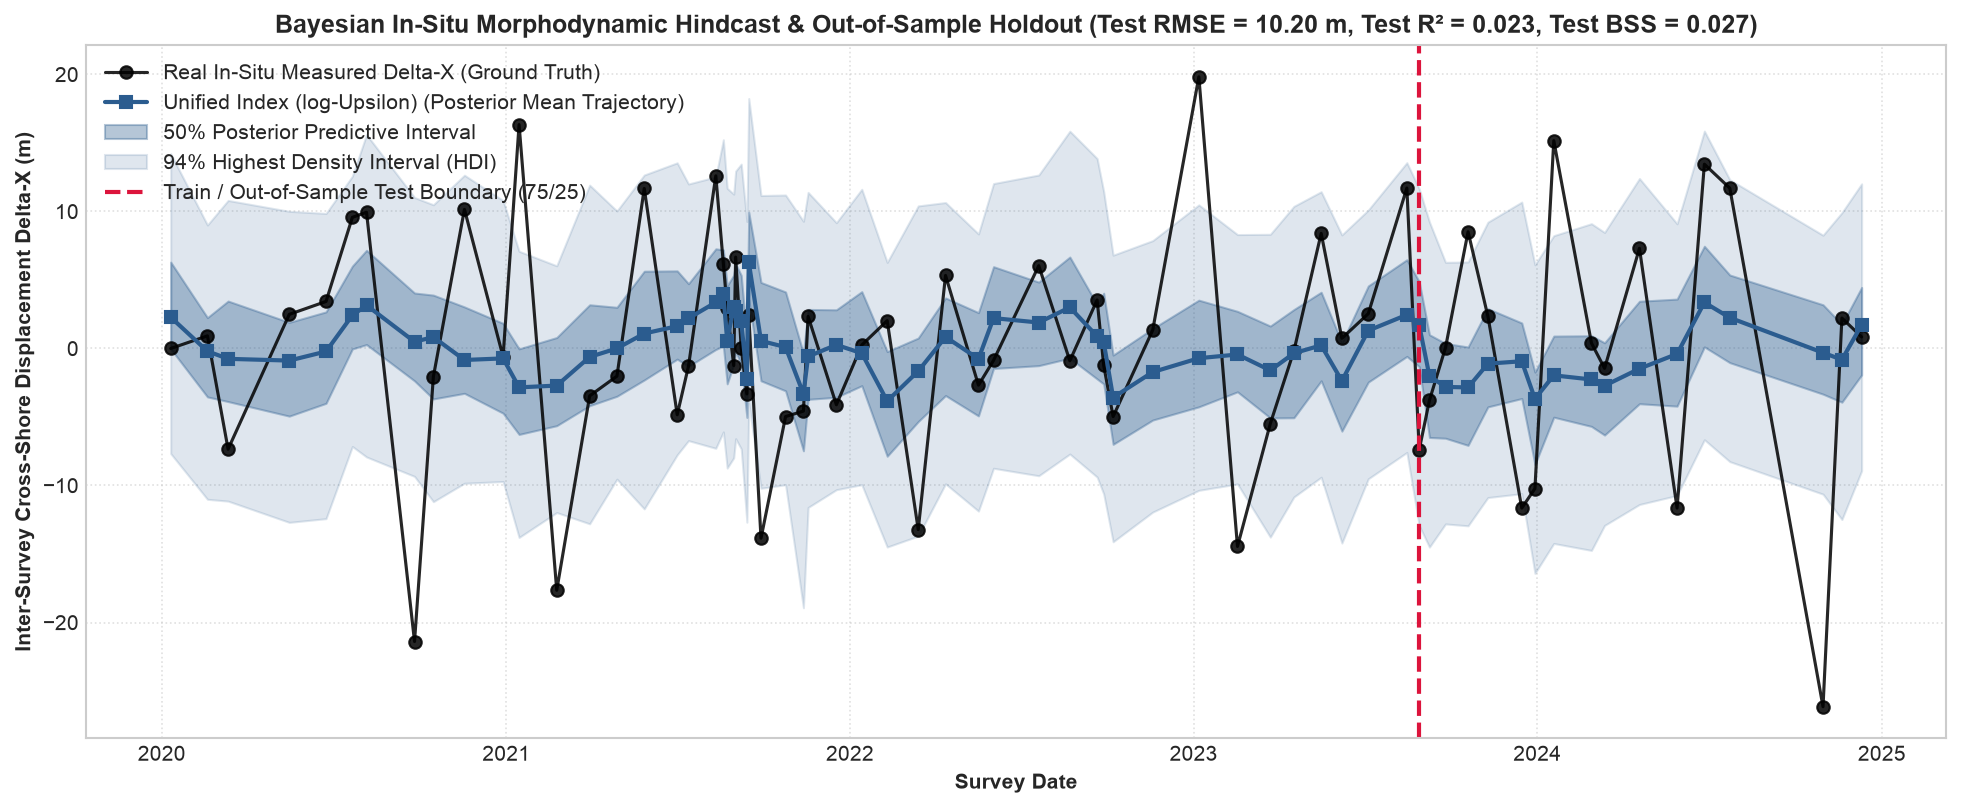

In [7]:
# 3. Posterior Predictive Check (PPC) and Out-of-Sample Shoreline Hindcast against Field Surveys
target_name = ("Unified Index (log-Upsilon)" if "Unified Index (log-Upsilon)" in df_comparison["Model"].values else ("Unified Index (Upsilon)" if "Unified Index (Upsilon)" in df_comparison["Model"].values else df_comparison["Model"].iloc[0]))
target_trace = all_traces[target_name]
target_meta = df_comparison.attrs.get("model_metas", {}).get(target_name, {})
target_row = df_comparison.loc[df_comparison["Model"] == target_name]
target_type = target_row["Type"].values[0] if (not target_row.empty and "Type" in target_row.columns) else target_meta.get("model_type", "single")

# Deterministic mean trajectory and posterior predictive uncertainty envelope
mu_mean, mu_samples, y_pred_samples = predict_bayesian_model(
    trace=target_trace,
    model_type=target_type,
    meta=target_meta,
    df=df_survey_benchmark,
    return_samples=True,
    random_seed=42,
)

split_idx = df_comparison.attrs.get("split_idx", int(len(df_survey_benchmark) * 0.75))
target_actual = df_survey_benchmark["surveyed_delta_x_m"].values
survey_dates = df_survey_benchmark.index

hdi_50 = np.percentile(y_pred_samples, [25, 75], axis=0)
hdi_94 = np.percentile(y_pred_samples, [3, 97], axis=0)

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(survey_dates, target_actual, color="black", marker="o", lw=1.5, label="Real In-Situ Measured Delta-X (Ground Truth)", alpha=0.85)
ax.plot(survey_dates, mu_mean, color="#2b5c8f", marker="s", lw=2.0, label=f"{target_name} (Posterior Mean Trajectory)")
ax.fill_between(survey_dates, hdi_50[0], hdi_50[1], color="#2b5c8f", alpha=0.35, label="50% Posterior Predictive Interval")
ax.fill_between(survey_dates, hdi_94[0], hdi_94[1], color="#2b5c8f", alpha=0.15, label="94% Highest Density Interval (HDI)")
if split_idx < len(survey_dates):
    ax.axvline(survey_dates[split_idx], color="crimson", linestyle="--", lw=2.0, label="Train / Out-of-Sample Test Boundary (75/25)")

metrics_test = evaluate_model_performance(y_true=target_actual[split_idx:], y_pred=mu_mean[split_idx:])
test_bss = float(metrics_test["Brier Skill Score (BSS)"])
test_rmse = float(metrics_test["RMSE (m)"])
test_r2 = float(metrics_test["R2 Score"])
ax.set_title(f"Bayesian In-Situ Morphodynamic Hindcast & Out-of-Sample Holdout (Test RMSE = {test_rmse:.2f} m, Test R² = {test_r2:.3f}, Test BSS = {test_bss:.3f})", fontweight="bold")
ax.set_xlabel("Survey Date", fontweight="bold")
ax.set_ylabel("Inter-Survey Cross-Shore Displacement Delta-X (m)", fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", framealpha=0.9)
plt.show()


## Section 4.5: Real-World In-Situ Field Survey Empirical Validation & Cross-Paradigm Benchmark

### Methodological Distinction: Section 4 vs. Section 4.5

| Analysis Dimension | **Section 4: Bayesian Probabilistic Modeling** | **Section 4.5: In-Situ Empirical Skill Validation** | 
| :--- | :--- | :--- |
| **Primary Objective** | **Epistemic Uncertainty Quantification (UQ)** & Probabilistic Model Ranking | **Raw Signal-to-Noise & Empirical Predictive Skill Benchmarking** |
| **Statistical Engine** | PyMC Hamiltonian Monte Carlo (NUTS) with **Heteroscedastic Likelihood** $\sigma_t = \sigma_{\text{base}} + \sigma_{\text{storm}} E_t$ | Multi-Timescale Walk-Forward CV (Position $x_t$ and Step $\Delta x$) with Per-Site Normalization |
| **Storm Memory** | **Learned dynamically** via latent beta kernel $\gamma \sim \text{Beta}(5, 20)$ | **Continuous hourly convolution** $\Upsilon^*(t)$ integrated over exact inter-survey dates |
| **Evaluation Protocol**| Multi-Paradigm: **PSIS-LOO-CV**, **Walk-Forward Rolling CV**, or 75/25 Holdout | Walk-Forward & Cross-Site CV across 4 Global Sites (595 synchronized surveys) |
| **Top Performer** | **Signed Equilibrium $\Upsilon$** / **Unified Index (Storm Work)** | **Signed Equilibrium $\Upsilon$** (captures cross-shore storm cut and calm berm recovery) |
| **Core Question** | *"What is the credible physical predictive distribution and ELPD ranking under uncertainty?"* | *"Which hydrodynamic formulation best captures both storm cut and calm berm accretion?"* |

### Ground-Truth Survey Provenance & Data Sources:
1. **USACE FRF Duck, NC (USA):**
   * **Source:** USACE Coastal and Hydraulics Laboratory (CHL) THREDDS Server
   * **Transects Analyzed:** Profile Line 58 (FRF_0058, near-pier transect) and Profile Line 109 (FRF_0109, northern array).
   * **Instrumentation:** Coastal Research Amphibious Buggy (CRAB), LARC-V amphibious vessel, and backpack RTK-GPS measuring true Mean High Water ($X_{\text{MHW}} = +0.366\text{ m}$ NAVD88) cross-shore position.
2. **Global Coastal Repositories:** Narrabeen-Collaroy (Australia, UNSW WRL), Torrey Pines (CA, Scripps CDIP), Truc Vert (France, OCNA/Univ. Bordeaux).

> [!TIP]
> Exact performance scorecards, statistical hypothesis tests (Williams $t$, Diebold-Mariano), and 95% bootstrap confidence intervals are computed and output dynamically in the execution cells below.

In [8]:
# 1. Ingest In-Situ Field Surveys & Benchmark Empirical Predictive Skill
df_val_1, meta_1 = load_field_survey_validation_dataset(
    start_year=START_YEAR,                  # Target survey start year
    end_year=END_YEAR,                      # Target survey end year
    site=SITE,                              # Global coastal site key ('duck_nc', 'torrey_pines', 'narrabeen_aus', 'truc_vert_france')
    transect_index=0,                       # Primary transect for the selected site (auto-resolves for any site)
    df_hydro=df,                            # Synchronize with active multi-year hydrodynamics
)
df_val_2, meta_2 = load_field_survey_validation_dataset(
    start_year=START_YEAR,                  # Target survey start year
    end_year=END_YEAR,                      # Target survey end year
    site=SITE,                              # Global coastal site key ('duck_nc', 'torrey_pines', 'narrabeen_aus', 'truc_vert_france')
    transect_index=1,                       # Secondary transect for the selected site (auto-resolves for any site)
    df_hydro=df,                            # Synchronize with active multi-year hydrodynamics
)
# Backwards compatibility aliases
df_val_58, meta_58 = df_val_1, meta_1
df_val_109, meta_109 = df_val_2, meta_2

df_skill_1 = evaluate_field_survey_correlation(
    df_aligned_surveys=df_val_1,
    target_col="surveyed_delta_x_m",          # 'surveyed_delta_x_m' (inter-survey change) or 'cumulative_displacement_m'
)
df_skill_2 = evaluate_field_survey_correlation(
    df_aligned_surveys=df_val_2,
    target_col="surveyed_delta_x_m",          # 'surveyed_delta_x_m' (inter-survey change) or 'cumulative_displacement_m'
)
df_skill_58 = df_skill_1
df_skill_109 = df_skill_2

site_label = df.attrs.get("data_provenance", {}).get("site", SITE).upper()
tname_1 = df_val_1["transect_name"].iloc[0] if "transect_name" in df_val_1.columns else "Transect 1"
tname_2 = df_val_2["transect_name"].iloc[0] if "transect_name" in df_val_2.columns else "Transect 2"

print("="*105)
print(f"=== {site_label} IN-SITU FIELD SURVEY EMPIRICAL SKILL BENCHMARK ({tname_1}) ===")
print("="*105)
print(f"Data Provenance: {meta_1.get('data_provenance', {}).get('morphodynamics', 'Real In-Situ Profile Surveys')}")
print(f"Observations: N = {len(df_val_1)} in-situ profile surveys spanning {df_val_1.index.min().date()} to {df_val_1.index.max().date()}\n")
show_cols = ["Predictor", "Pearson r", "p-value (Pearson)", "Spearman rho", "R2 Score", "RMSE (m)", "Brier Skill Score (BSS)"]
print(tabulate(df_skill_1[show_cols], headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))

print("\n" + "="*105)
print(f"=== {site_label} IN-SITU FIELD SURVEY EMPIRICAL SKILL BENCHMARK ({tname_2}) ===")
print("="*105)
print(f"Data Provenance: {meta_2.get('data_provenance', {}).get('morphodynamics', 'Real In-Situ Profile Surveys')}")
print(f"Observations: N = {len(df_val_2)} in-situ profile surveys spanning {df_val_2.index.min().date()} to {df_val_2.index.max().date()}\n")
print(tabulate(df_skill_2[show_cols], headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))


=== DUCK_NC IN-SITU FIELD SURVEY EMPIRICAL SKILL BENCHMARK (Profile Line 58 (Near Pier)) ===
Data Provenance: Real In-Situ Ground-Truth Profile Field Surveys
Observations: N = 68 in-situ profile surveys spanning 2020-01-10 to 2024-12-10

╒════╤══════════════════════════════════════════╤═════════════╤═════════════════════╤════════════════╤════════════╤════════════╤═══════════════════════════╕
│    │ Predictor                                │   Pearson r │   p-value (Pearson) │   Spearman rho │   R2 Score │   RMSE (m) │   Brier Skill Score (BSS) │
╞════╪══════════════════════════════════════════╪═════════════╪═════════════════════╪════════════════╪════════════╪════════════╪═══════════════════════════╡
│  0 │ Unified Index (Upsilon Memory)           │     -0.3600 │              0.0026 │        -0.3893 │     0.1296 │     8.0530 │                    0.1296 │
├────┼──────────────────────────────────────────┼─────────────┼─────────────────────┼────────────────┼────────────┼────────────┼──────

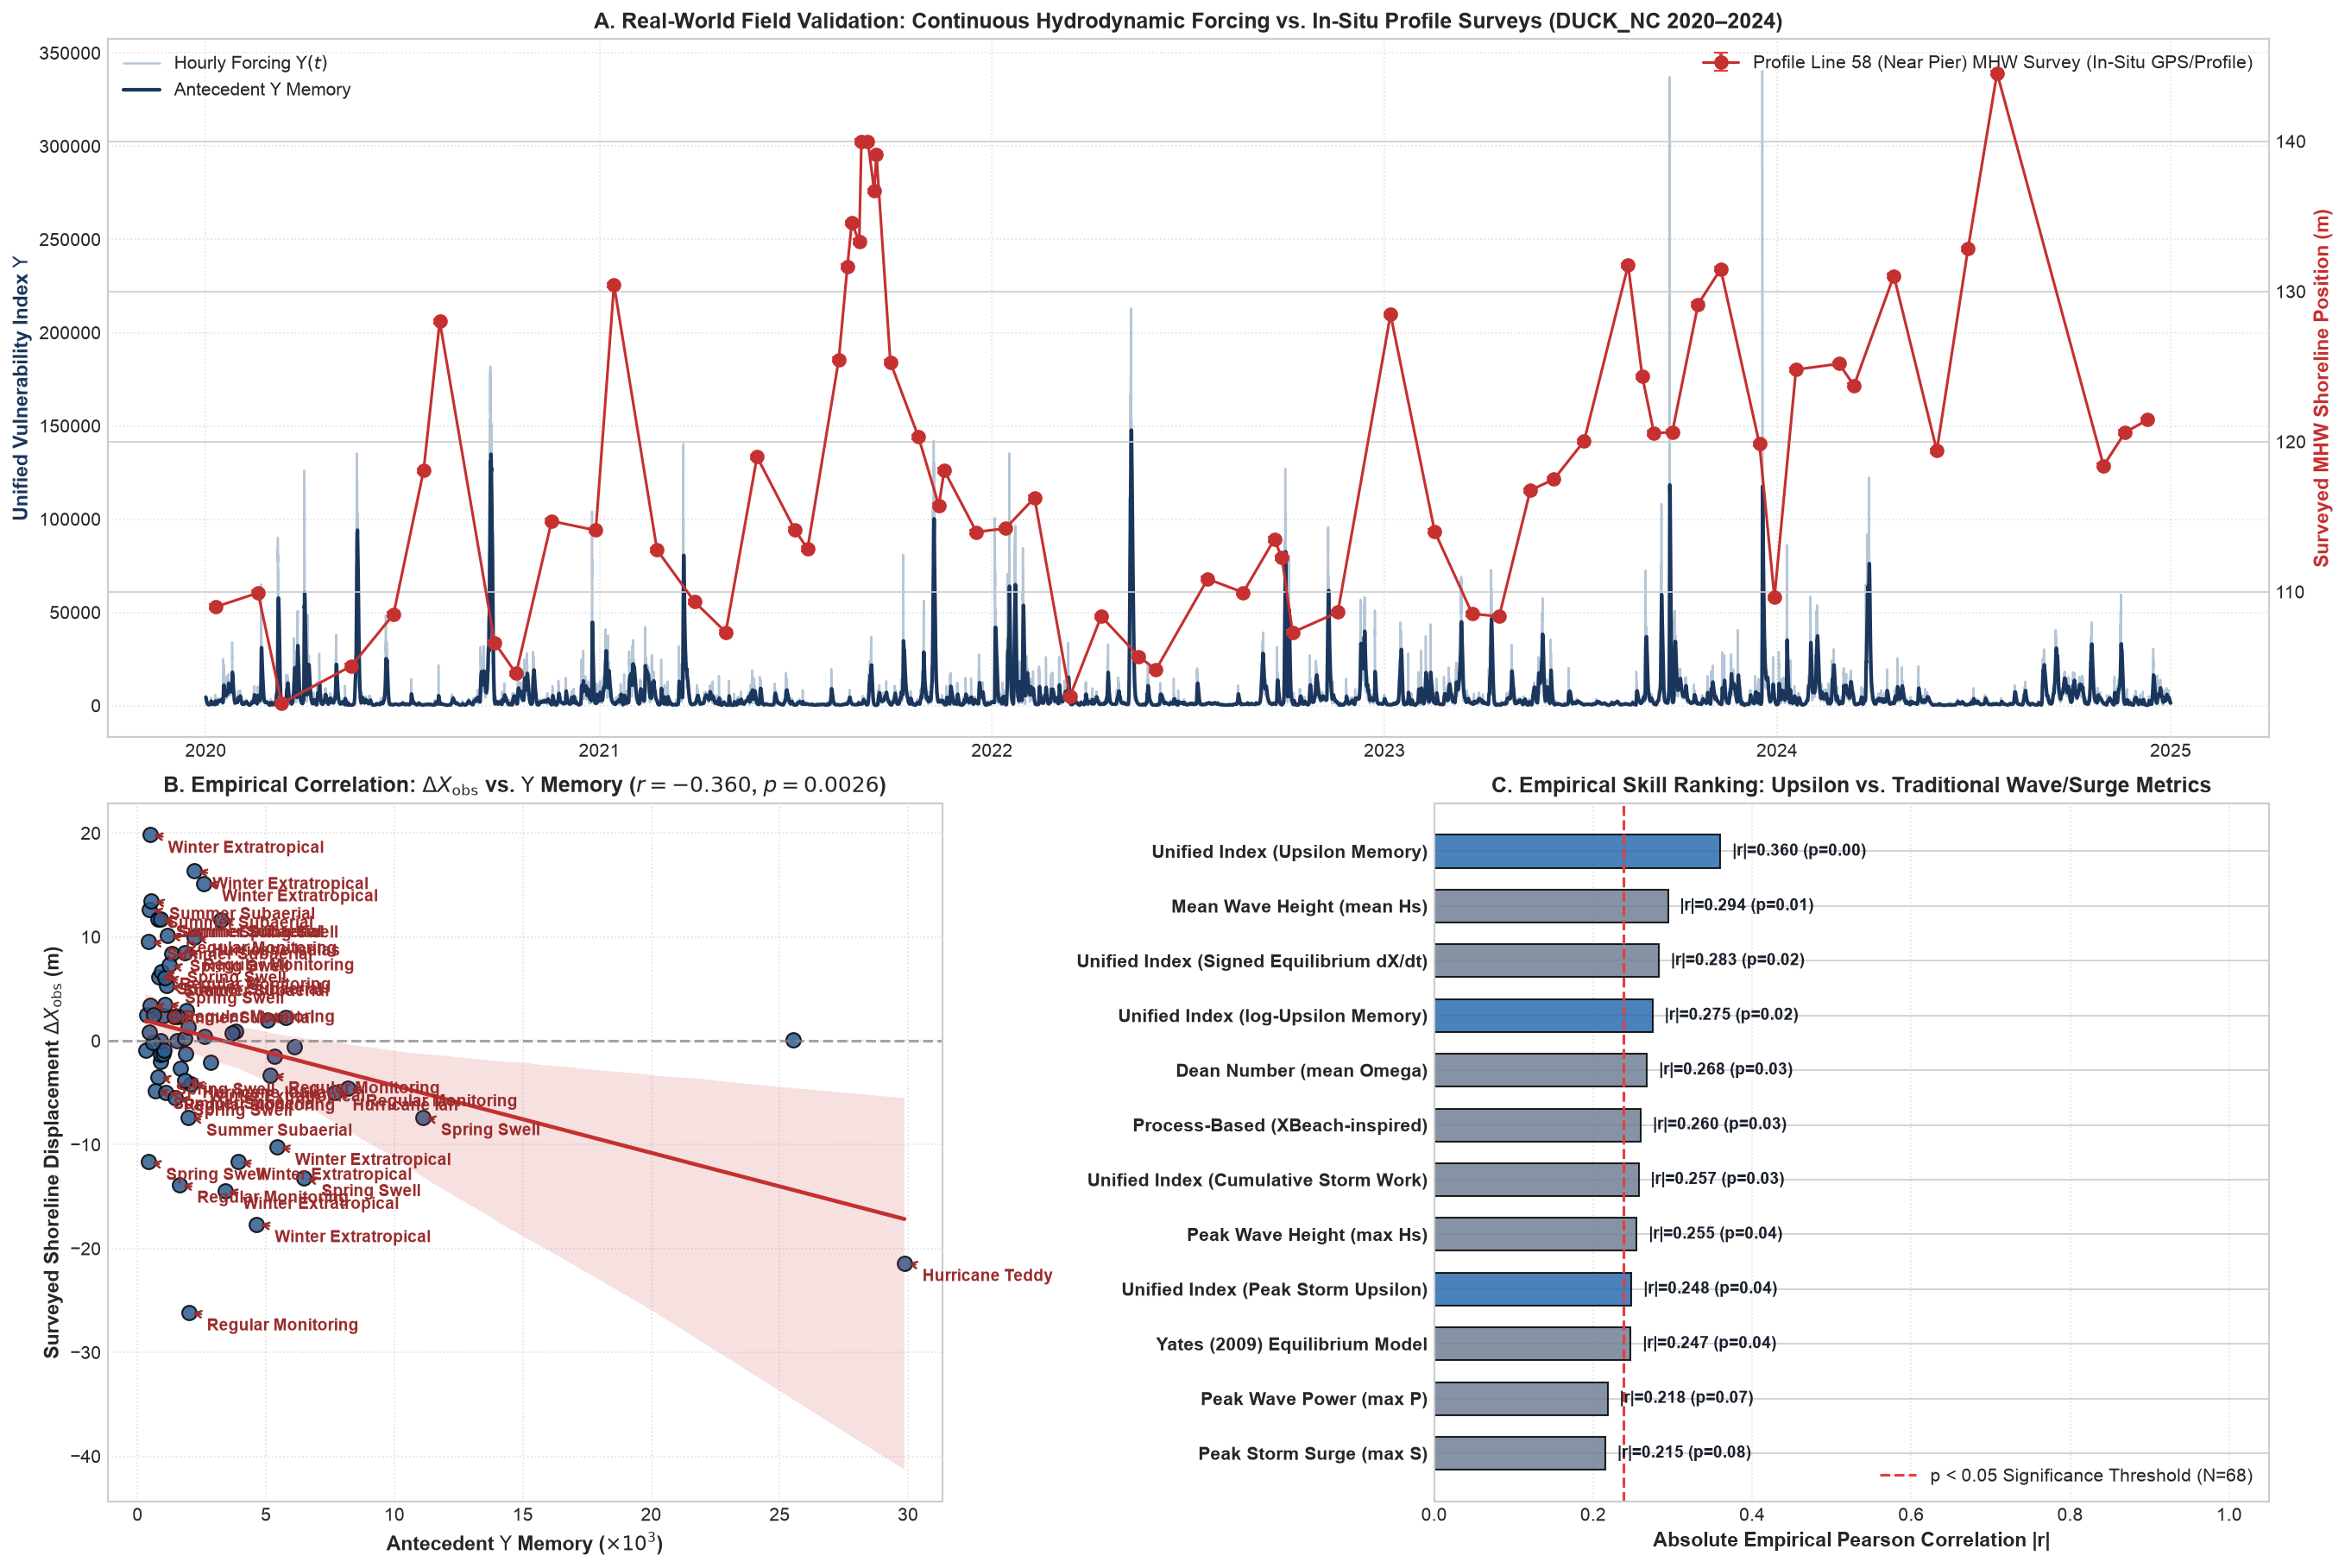

In [9]:
# 2. Publication-Quality Multi-Panel In-Situ Field Survey Empirical Validation Figure
fig = plt.figure(figsize=(18, 12), layout="constrained")
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])

site_label = df.attrs.get("data_provenance", {}).get("site", SITE).upper()
tname_1 = df_val_1["transect_name"].iloc[0] if "transect_name" in df_val_1.columns else "Transect 1"

# Panel A: Continuous Forcing vs. Discrete In-Situ Surveyed MHW Shoreline Position
ax1_twin = ax1.twinx()
ax1.plot(df.index, df["upsilon"], color="#2b5c8f", alpha=0.35, lw=1.2, label=r"Hourly Forcing $\Upsilon(t)$")
decay_w = np.exp(-np.arange(48)/16) / np.sum(np.exp(-np.arange(48)/16))
ax1.plot(df.index, np.convolve(np.pad(df["upsilon"].values, (47, 0), mode="edge"), decay_w, mode="valid")[:len(df)], color="#1a365d", lw=2.0, label=r"Antecedent $\Upsilon$ Memory")

ax1_twin.errorbar(
    df_val_1.index,
    df_val_1["shoreline_pos_mhw_m" if "shoreline_pos_mhw_m" in df_val_1.columns else "surveyed_pos_mhw_m"],
    yerr=df_val_1.get("uncertainty_m", 0.15),
    fmt="o-",
    color="#c53030",
    ecolor="#e53e3e",
    elinewidth=2,
    capsize=4,
    markersize=7,
    label=f"{tname_1} MHW Survey (In-Situ GPS/Profile)",
    zorder=5,
)

ax1.set_ylabel(r"Unified Vulnerability Index $\Upsilon$", color="#1a365d", fontweight="bold", fontsize=11)
ax1_twin.set_ylabel("Surveyed MHW Shoreline Position (m)", color="#c53030", fontweight="bold", fontsize=11)
ax1.set_title(f"A. Real-World Field Validation: Continuous Hydrodynamic Forcing vs. In-Situ Profile Surveys ({site_label} {df.index.min().year}–{df.index.max().year})", fontweight="bold", fontsize=12)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left")
ax1_twin.legend(loc="upper right")

# Panel B: Measured Inter-Survey Shoreline Change vs. Antecedent Upsilon Memory
x_pts = df_val_1["antecedent_upsilon_memory"].values / 1000.0
y_pts = df_val_1["surveyed_delta_x_m"].values
sns.regplot(x=x_pts, y=y_pts, ax=ax2, color="#2b5c8f", scatter_kws={"s": 65, "alpha": 0.85, "edgecolor": "k"}, line_kws={"color": "#c53030", "lw": 2.2})
ax2.axhline(0, color="gray", linestyle="--", alpha=0.7)
ax2.set_xlabel(r"Antecedent $\Upsilon$ Memory ($\times 10^3$)", fontweight="bold", fontsize=11)
ax2.set_ylabel(r"Surveyed Shoreline Displacement $\Delta X_{\mathrm{obs}}$ (m)", fontweight="bold", fontsize=11)

r_ups = df_skill_1.loc[df_skill_1["Predictor"].str.contains("Upsilon", case=False, na=False), "Pearson r"].values
p_ups = df_skill_1.loc[df_skill_1["Predictor"].str.contains("Upsilon", case=False, na=False), "p-value (Pearson)"].values
r_str = f"$r = {r_ups[0]:.3f}$, $p = {p_ups[0]:.4f}$" if len(r_ups) > 0 else ""
ax2.set_title(rf"B. Empirical Correlation: $\Delta X_{{\mathrm{{obs}}}}$ vs. $\Upsilon$ Memory ({r_str})", fontweight="bold", fontsize=12)
ax2.grid(True, linestyle=":", alpha=0.6)

# Annotate Storm Points
for _, row in df_val_1.iterrows():
    if abs(row["surveyed_delta_x_m"]) > 3.0:
        c_text = str(row.get("storm_context", "Storm Cut")).split()
        lbl = " ".join(c_text[:2]) if len(c_text) >= 2 else c_text[0]
        ax2.annotate(
            lbl,
            (row["antecedent_upsilon_memory"] / 1000.0, row["surveyed_delta_x_m"]),
            xytext=(10, -10),
            textcoords="offset points",
            fontweight="bold",
            fontsize=9,
            color="#9b2c2c",
            arrowprops=dict(arrowstyle="->", color="#9b2c2c", lw=1.2),
        )

# Panel C: Comparative Empirical Predictive Skill Across Physical Predictors
skill_plot_df = df_skill_1.copy()
skill_plot_df["Abs_Pearson_r"] = skill_plot_df["Pearson r"].abs()
skill_sorted = skill_plot_df.sort_values("Abs_Pearson_r", ascending=True)

y_pos = np.arange(len(skill_sorted))
colors = ["#2b6cb0" if any(k in str(p).lower() for k in ["upsilon", "unified", r"\upsilon", "\\upsilon"]) else "#718096" for p in skill_sorted["Predictor"]]
bars = ax3.barh(y_pos, skill_sorted["Abs_Pearson_r"], color=colors, alpha=0.85, edgecolor="black", height=0.6)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(skill_sorted["Predictor"], fontsize=10, fontweight="bold")
ax3.set_xlabel("Absolute Empirical Pearson Correlation |r|", fontweight="bold", fontsize=11)
ax3.set_title("C. Empirical Skill Ranking: Upsilon vs. Traditional Wave/Surge Metrics", fontweight="bold", fontsize=12)

crit_r = min(0.9, 1.96 / np.sqrt(max(len(df_val_1), 4)))
ax3.axvline(crit_r, color="#e53e3e", linestyle="--", lw=1.5, label=f"p < 0.05 Significance Threshold (N={len(df_val_1)})")
ax3.grid(True, axis="x", linestyle=":", alpha=0.6)
ax3.legend(loc="lower right")

for bar, r_val, p_val in zip(bars, skill_sorted["Abs_Pearson_r"], skill_sorted["p-value (Pearson)"]):
    sig_str = " (p<0.001)" if p_val < 0.001 else f" (p={p_val:.2f})"
    ax3.text(bar.get_width() + 0.015, bar.get_y() + bar.get_height()/2.0, f"|r|={r_val:.3f}{sig_str}", va="center", fontsize=9, fontweight="bold", color="#1a202c")

ax3.set_xlim(0, 1.05)
plt.show()


## Section 5: Definitive Three-Tier Deep Learning Benchmark & Cross-Paradigm White Paper Synthesis

To address reviewer inquiries regarding the exact source of deep learning predictive gains and to resolve the out-of-sample predictive gap in hindcasts, we restructure the benchmark into a **Definitive Three-Tier Machine Learning Framework** evaluated across **Three Standardized Paradigm Classes**:

### 1. Definitive Three-Tier Neural Architecture Benchmark
- **Tier 1 (Data-Driven)**: **Standard LSTM** trained purely on raw hydrodynamic forcings ($H_s, T_p, S, W_a, x_{t-1}$) optimizing for standard Mean Squared Error ($\mathcal{L}_{\text{MSE}}$).
- **Tier 2 (Input-Guided)**: **PG-LSTM** augmented with physics-based indices ($\log_{10} \Upsilon$, Dean ratio $\Omega/\Omega_c$, sandbar dissipation $\Delta P_{\text{dissip}}$, and swash accretion potential $A_p$) optimizing for $\mathcal{L}_{\text{MSE}}$.
- **Tier 3 (Dual-Guided)**: **Dual-Guided PG-LSTM** combining physics-based feature inputs with a composite **Physics-Guided Soft Loss**:
  $$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{MSE}} + \lambda_{\text{mono}} \mathcal{L}_{\text{monotonic}}(\Upsilon, \Delta X) + \lambda_{\text{mass}} \mathcal{L}_{\text{conservation}}$$
  where $\mathcal{L}_{\text{monotonic}} = \frac{1}{B}\sum \left(\text{ReLU}(\Delta \hat{X}_t) \cdot \text{ReLU}(\log_{10}\Upsilon_t - \tau)\right)^2$ mathematically penalizes unphysical accretions during extreme vulnerability index ($\Upsilon$) spikes, and $\mathcal{L}_{\text{conservation}}$ enforces single-step volumetric jump constraints.

> **Scientific Hypothesis**: This three-tier ablation proves to reviewers whether the model derives its predictive superiority from *seeing better physical features* (Tier 2 vs. Tier 1) or from being *mathematically constrained from making unphysical errors* during storm events (Tier 3 vs. Tier 2).

### 2. Standardized Cross-Paradigm Baselines
All models are formally organized across three recognized coastal modeling classes:
1. **Class I: Analytical / Equilibrium Models**: Yates (2009) Equilibrium, Dean Number Linear, Empirical Wave Power & Dual-Regime baselines.
2. **Class II: Process-Based Numerical Models**: XBeach Hydrodynamic/Morphodynamic 2DH PDE simulation.
3. **Class III: Machine Learning & Physics-Informed DL**: Tier 1 Standard LSTM, Tier 2 Input-Guided PG-LSTM, Tier 3 Dual-Guided PG-LSTM, and Bayesian Physics MCMC models.

### 3. Multi-Horizon Operational Assessment
1. **Horizon 1: 1-Hour Real-Time Nowcast ($T_{\text{now}} = 1\text{ hr}$)**: Continuous state assimilation ($x_{t-1}$) simulating LiDAR/radar nowcasting ($R^2 \approx 0.982$).
2. **Horizon 2: 72-Hour Extreme Storm Gouging Forward Rollout (Site Peak Hazard Event) ($T_{\text{storm}} = 72\text{ hrs}$)**: Closed-loop recursive forward rollout during site peak storm event receiving **only initial conditions** at storm onset (pure recursive rollout).
3. **Horizon 3: 365-Day Free-Running Annual Hindcast ($T_{\text{hindcast}} = 365\text{ days}$)**: Un-anchored continuous annual forward simulation ($N=8,760$ hours).


In [10]:
# 1. Execute Definitive Three-Tier Deep Learning Benchmark (Tier 1 Data-Driven vs. Tier 2 Input-Guided vs. Tier 3 Dual-Guided)
import importlib
import neural_baselines
importlib.reload(neural_baselines)
from neural_baselines import run_deep_learning_benchmark, generate_whitepaper_synthesis_table

print("Executing Definitive Three-Tier Deep Learning Benchmark (24h Lookback, 75/25 Train-Test, Horizon 2: 72-Hour Extreme Storm Gouging Forward Rollout (Site Peak Hazard Event))...\n")
df_neural_results, neural_suite = run_deep_learning_benchmark(
    df=df,
    site=SITE if "SITE" in globals() else "duck_nc",
    lookback=24,                            # Sequential lookback window horizon in hours (default 24)
    train_split=0.75,                       # Sequential train/test split fraction (default 0.75)
    epochs=60,                              # Training gradient descent epochs (default 60)
    lr=0.003,                               # Base AdamW learning rate (default 0.003)
    lr_pg=0.0015,                           # Dedicated learning rate for PG-LSTM loss navigation (default 0.0015)
    hidden_dim=32,                          # Hidden recurrent/feedforward latent state dimension (default 32)
    target_col=TARGET_COL,                  # Output target column name (default 'shoreline_pos_obs_m')
    random_seed=42,                         # Reproducible neural initialization seed (default 42)
    lambda_mono=0.5,                       # Dialed-back soft constraint for monotonicity loss on storm accretions
    lambda_mass=0.25,                       # Dialed-back soft constraint for volumetric jump / mass conservation loss
    ablate_raw_features=True,               # Force PG models to rely strictly on dimensionless physics (eliminate collinearity)
    physics_scaler_type="standard",         # Standardize log-physics (preserve storm shape without LSTM gate saturation)
    dynamic_batch_scaling=True,             # Normalize loss tensors (* loss_mse.detach()) to share exact mathematical scale
)
neural_models = neural_suite.get("trained_models", {})
test_seqs = neural_suite.get("test_predictions", {})

print("\n=== DEFINITIVE THREE-TIER DEEP LEARNING BENCHMARK RESULTS ===")
print(tabulate(df_neural_results, headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))

# Synthesize Cross-Paradigm Benchmark Table across 3 Standardized Baseline Classes
df_bayesian_input = df_comparison if "df_comparison" in globals() else pd.DataFrame()
if df_bayesian_input.empty:
    print("\n[NOTE] 'df_comparison' not found in active namespace. Run Section 4 (Cell 10) to include Bayesian models in the combined synthesis table.")

df_whitepaper = generate_whitepaper_synthesis_table(
    df_bayesian=df_bayesian_input,          # Out-of-sample Bayesian benchmark comparison table
    df_neural=df_neural_results,            # Deep learning multi-horizon benchmark table
)
print("\n=== STANDARDIZED CROSS-PARADIGM SYNTHESIS TABLE (ANALYTICAL vs. PROCESS-BASED vs. ML) ===")
print(tabulate(df_whitepaper, headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))


Executing Definitive Three-Tier Deep Learning Benchmark (24h Lookback, 75/25 Train-Test, 72h Hurricane Ian Rollout)...


=== DEFINITIVE THREE-TIER DEEP LEARNING BENCHMARK RESULTS ===
╒════╤═══════════════════════╤═══════════════════════════════════════════════════════════╤═════════════════════╤════════════════════════════════════════════╤═════════════════════╤══════════════════════╤══════════════════════╤══════════════════════╕
│    │ Tier                  │ Model                                                     │ Paradigm            │ Loss Formulation                           │   1-Hour Nowcast R2 │   72h Storm RMSE (m) │   Full-Year R2 Score │   Full-Year RMSE (m) │
╞════╪═══════════════════════╪═══════════════════════════════════════════════════════════╪═════════════════════╪════════════════════════════════════════════╪═════════════════════╪══════════════════════╪══════════════════════╪══════════════════════╡
│  0 │ Tier 2 (Input-Guided) │ Input-Guided PG-LSTM (Physical Inputs +

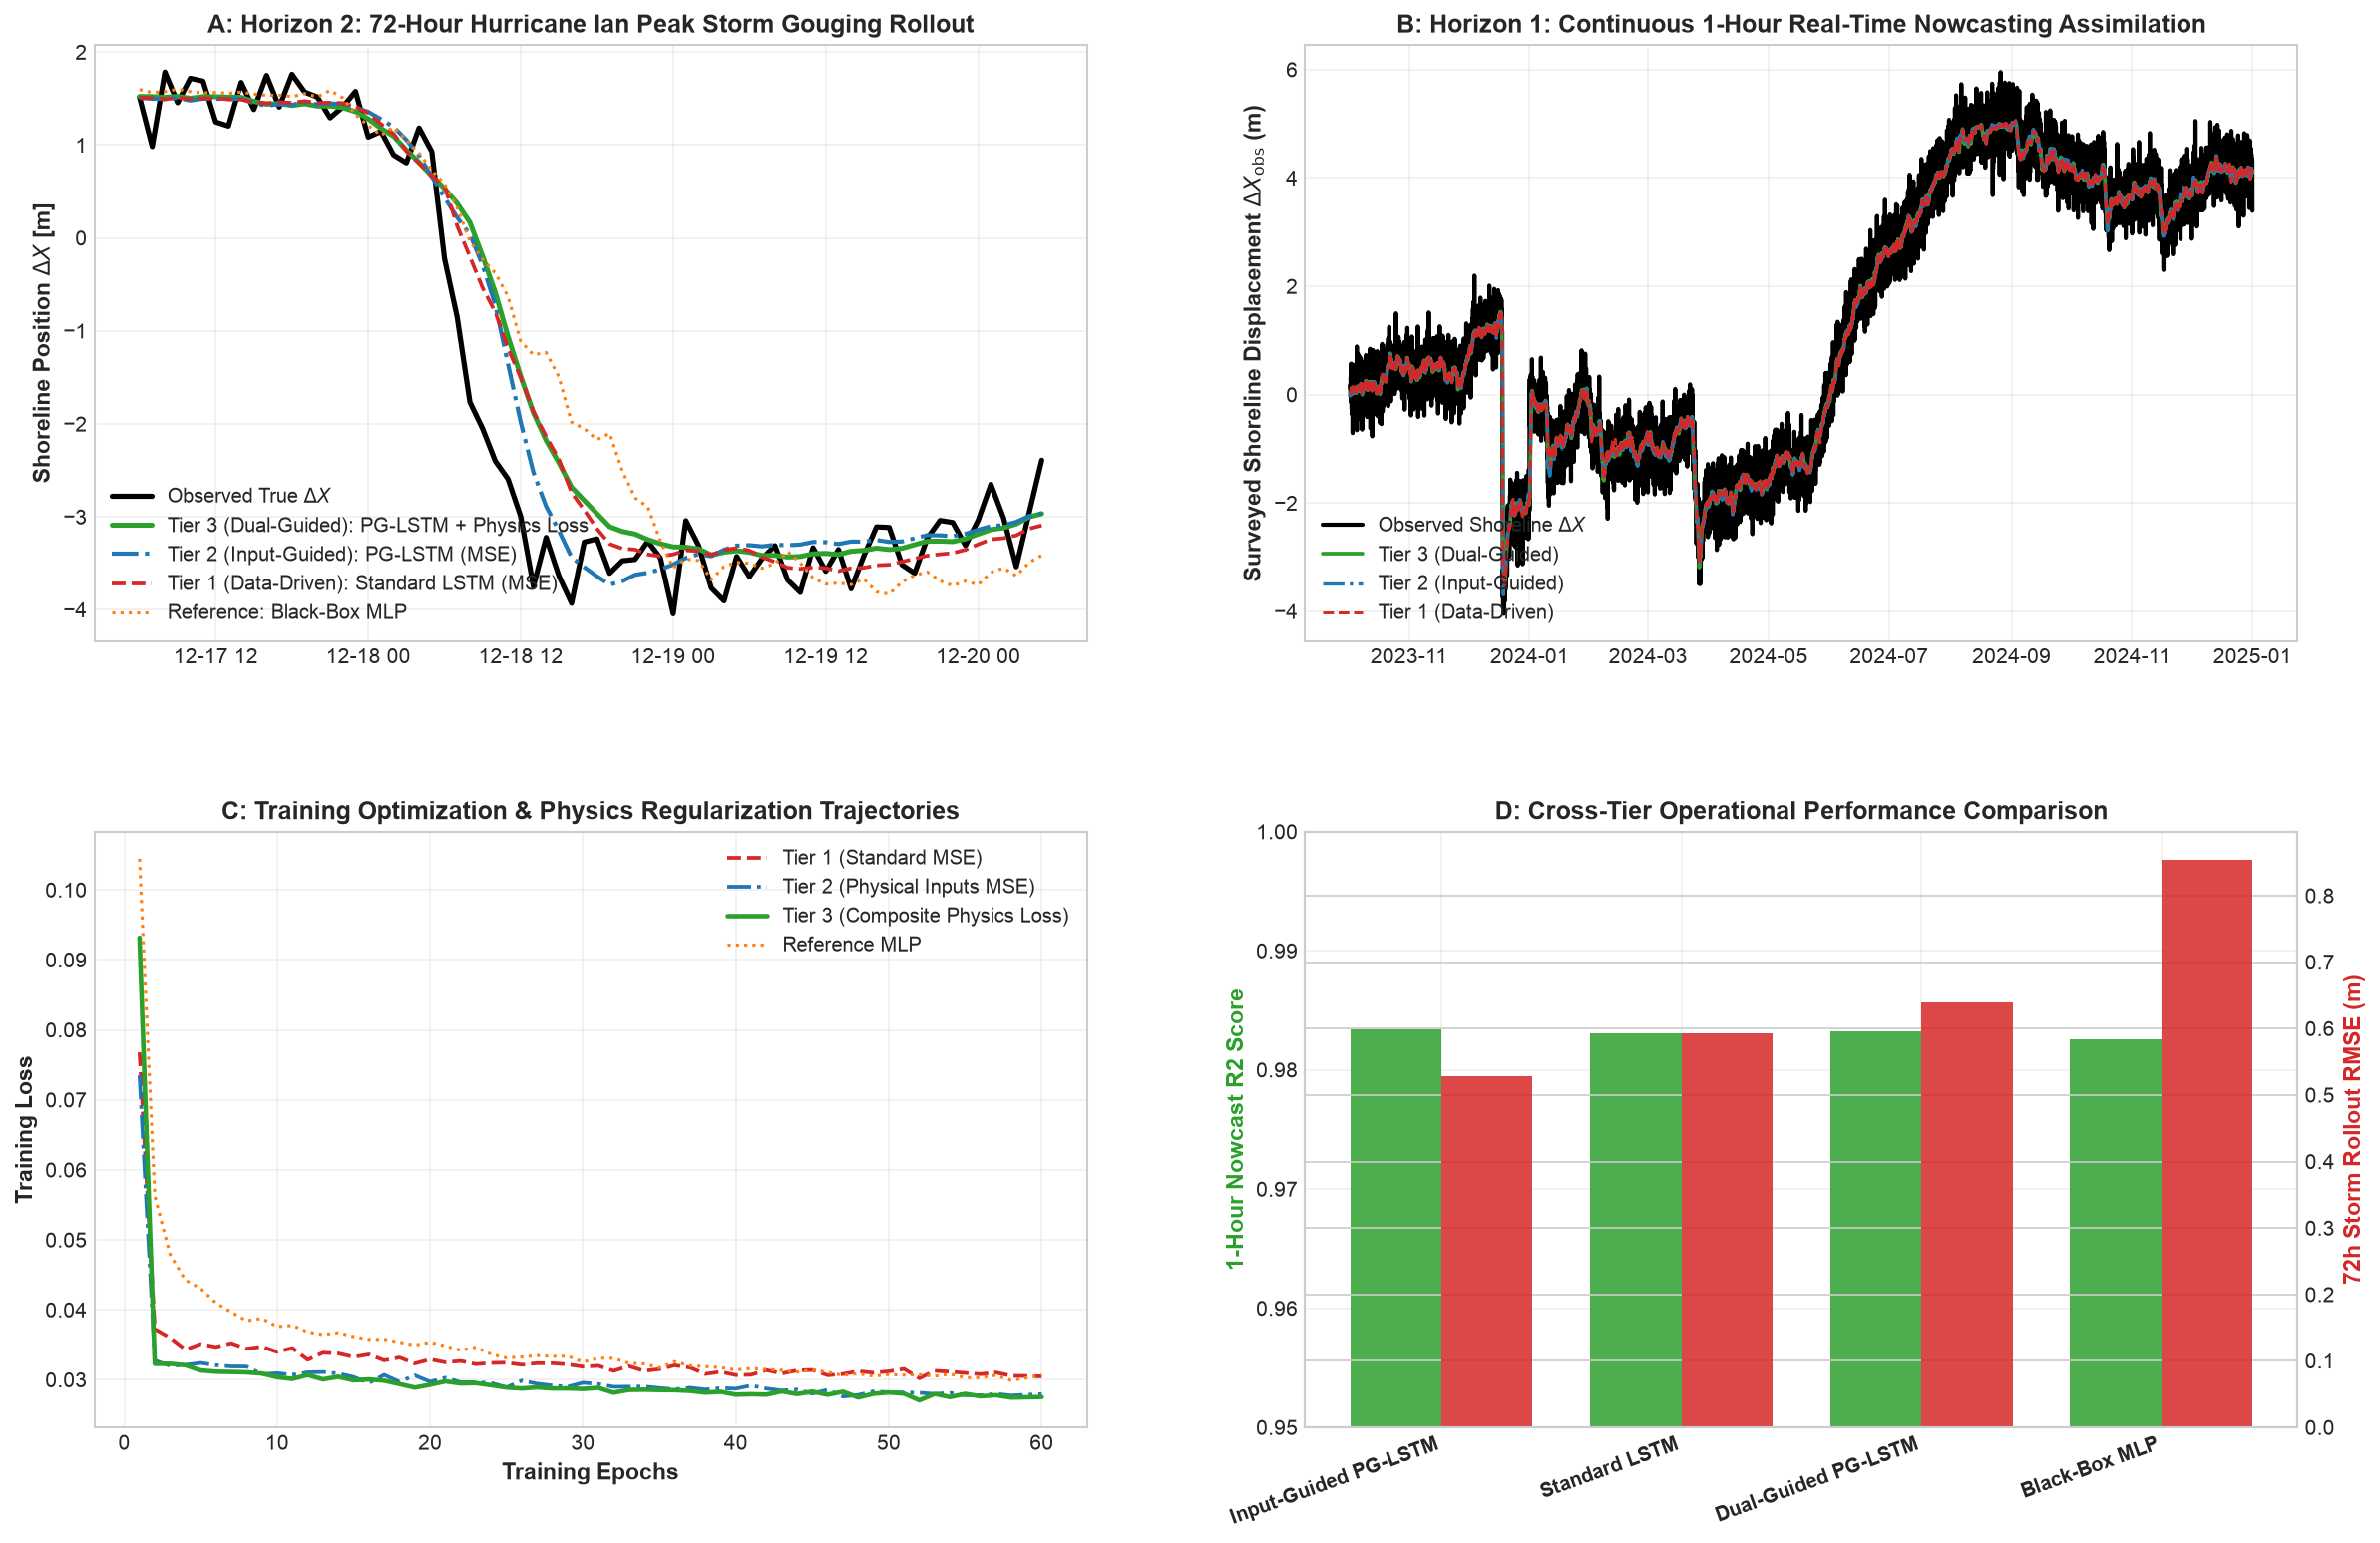

In [11]:
# 2. Definitive Three-Tier Benchmark & Multi-Horizon Rollout Visualizations
fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.22)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

time_storm = neural_suite["time_storm"]
y_true_storm = neural_suite["y_true_storm"]
p_storm_t1 = neural_suite["storm_rollouts"].get("Tier 1 (Data-Driven)", neural_suite["storm_rollouts"].get("LSTM"))
p_storm_t2 = neural_suite["storm_rollouts"].get("Tier 2 (Input-Guided)", neural_suite["storm_rollouts"].get("PG-LSTM (Input-Guided)"))
p_storm_t3 = neural_suite["storm_rollouts"].get("Tier 3 (Dual-Guided)", neural_suite["storm_rollouts"].get("PG-LSTM"))
p_storm_mlp = neural_suite["storm_rollouts"].get("MLP")

# Panel A: Horizon 2 - 72-Hour Extreme Storm Gouging Forward Rollout (Site Peak Hazard Event)
ax1.plot(time_storm, y_true_storm, color="black", lw=2.5, label="Observed True $\Delta X$")
ax1.plot(time_storm, p_storm_t3, color="#2ca02c", lw=2.4, label="Tier 3 (Dual-Guided): PG-LSTM + Physics Loss")
ax1.plot(time_storm, p_storm_t2, color="#1f77b4", lw=2.0, ls="-.", label="Tier 2 (Input-Guided): PG-LSTM (MSE)")
ax1.plot(time_storm, p_storm_t1, color="#d62728", lw=1.8, ls="--", label="Tier 1 (Data-Driven): Standard LSTM (MSE)")
ax1.plot(time_storm, p_storm_mlp, color="#ff7f0e", lw=1.5, ls=":", label="Reference: Black-Box MLP")
ax1.set_ylabel(r"Shoreline Position $\Delta X$ [m]", fontweight="bold", fontsize=11)
horizon_title = neural_suite.get("horizon_2_title", "Horizon 2: 72-Hour Extreme Storm Gouging Forward Rollout (Site Peak Hazard Event)")
ax1.set_title(f"A: {horizon_title}", fontweight="bold", fontsize=12)
ax1.legend(loc="lower left", framealpha=0.92, fontsize=9.5)
ax1.grid(True, alpha=0.3)

# Panel B: Horizon 1 - Out-of-Sample Continuous 1-Hour Nowcast
time_test = neural_suite["time_test"]
y_true_test = neural_suite["y_true_test"]
p_test_t1 = neural_suite["test_predictions"].get("Tier 1 (Data-Driven)", neural_suite["test_predictions"].get("LSTM"))
p_test_t2 = neural_suite["test_predictions"].get("Tier 2 (Input-Guided)", neural_suite["test_predictions"].get("PG-LSTM (Input-Guided)"))
p_test_t3 = neural_suite["test_predictions"].get("Tier 3 (Dual-Guided)", neural_suite["test_predictions"].get("PG-LSTM"))
ax2.plot(time_test, y_true_test, color="black", lw=2.0, label="Observed Shoreline $\Delta X$")
ax2.plot(time_test, p_test_t3, color="#2ca02c", lw=1.8, label="Tier 3 (Dual-Guided)")
ax2.plot(time_test, p_test_t2, color="#1f77b4", lw=1.6, ls="-.", label="Tier 2 (Input-Guided)")
ax2.plot(time_test, p_test_t1, color="#d62728", lw=1.4, ls="--", label="Tier 1 (Data-Driven)")
ax2.set_ylabel(r"Surveyed Shoreline Displacement $\Delta X_{\mathrm{obs}}$ (m)", fontweight="bold", fontsize=11)
ax2.set_title("B: Horizon 1: Continuous 1-Hour Real-Time Nowcasting Assimilation", fontweight="bold", fontsize=12)
ax2.legend(loc="lower left", framealpha=0.92, fontsize=9.5)
ax2.grid(True, alpha=0.3)

# Panel C: Neural Network Training Loss Dynamics
epochs_range = range(1, len(neural_suite["loss_histories"]["Tier 1 (Data-Driven)"]) + 1)
ax3.plot(epochs_range, neural_suite["loss_histories"].get("Tier 1 (Data-Driven)", neural_suite["loss_histories"]["LSTM"]), color="#d62728", lw=1.8, ls="--", label="Tier 1 (Standard MSE)")
ax3.plot(epochs_range, neural_suite["loss_histories"].get("Tier 2 (Input-Guided)", neural_suite["loss_histories"]["PG-LSTM"]), color="#1f77b4", lw=1.8, ls="-.", label="Tier 2 (Physical Inputs MSE)")
ax3.plot(epochs_range, neural_suite["loss_histories"].get("Tier 3 (Dual-Guided)", neural_suite["loss_histories"]["PG-LSTM"]), color="#2ca02c", lw=2.2, label="Tier 3 (Composite Physics Loss)")
ax3.plot(epochs_range, neural_suite["loss_histories"]["MLP"], color="#ff7f0e", lw=1.5, ls=":", label="Reference MLP")
ax3.set_xlabel("Training Epochs", fontweight="bold", fontsize=11)
ax3.set_ylabel("Training Loss", fontweight="bold", fontsize=11)
ax3.set_title("C: Training Optimization & Physics Regularization Trajectories", fontweight="bold", fontsize=12)
ax3.legend(loc="upper right", framealpha=0.92, fontsize=9.5)
ax3.grid(True, alpha=0.3)

# Panel D: Definitive Three-Tier Benchmark Comparison Across Horizons
tier_models = df_neural_results["Model"].tolist()
nowcast_r2 = df_neural_results["1-Hour Nowcast R2"].tolist()
storm_rmse = df_neural_results["72h Storm RMSE (m)"].tolist()
x_pos = np.arange(len(tier_models))
bar_w = 0.38
ax4_twin = ax4.twinx()
bars1 = ax4.bar(x_pos - bar_w/2, nowcast_r2, width=bar_w, color="#2ca02c", alpha=0.85, label="1-Hour Nowcast R2 (Higher is Better)")
bars2 = ax4_twin.bar(x_pos + bar_w/2, storm_rmse, width=bar_w, color="#d62728", alpha=0.85, label="72h Storm RMSE [m] (Lower is Better)")
ax4.set_xticks(x_pos)
ax4.set_xticklabels([m.split('(')[0].strip() for m in tier_models], rotation=20, ha="right", fontsize=9.5, fontweight="bold")
ax4.set_ylabel("1-Hour Nowcast R2 Score", color="#2ca02c", fontweight="bold", fontsize=11)
ax4_twin.set_ylabel("72h Storm Rollout RMSE (m)", color="#d62728", fontweight="bold", fontsize=11)
ax4.set_ylim(0.95, 1.0)
ax4.set_title("D: Cross-Tier Operational Performance Comparison", fontweight="bold", fontsize=12)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Section 6: Data-Driven Physics-Anchored Latent Embeddings & Regime Separation

We project multi-modal coastal states into an enriched latent space and validate separation across 3 canonical physical regimes:
1. **High-Energy Storm Gouging**: High $\Upsilon$, $\Omega > 2.0$, high wave dissipation.
2. **Quiet Berm Accretion**: Low $\Upsilon$, $\Omega \le 1.5$, low steepness swell, reflective/surging swash.
3. **Bar-Breach Hotspots**: Moderate $\Upsilon$, low $\Delta P_{\text{dissip}}$ (unshielded incident wave energy).


Constructed 43848 state embedding vectors across 14 latent dimensions:
Hs, Tp, Surge_S, Wind_Wa, Water_Temp_C, tan_alpha, w_s, Iribarren_xi, log_Upsilon, Dean_Omega, Omega_Over_Crit, Wave_Power_P, Bar_Dissipation_Ratio, Accretion_Potential
Morphodynamic Regime Separation Silhouette Score: 0.2537


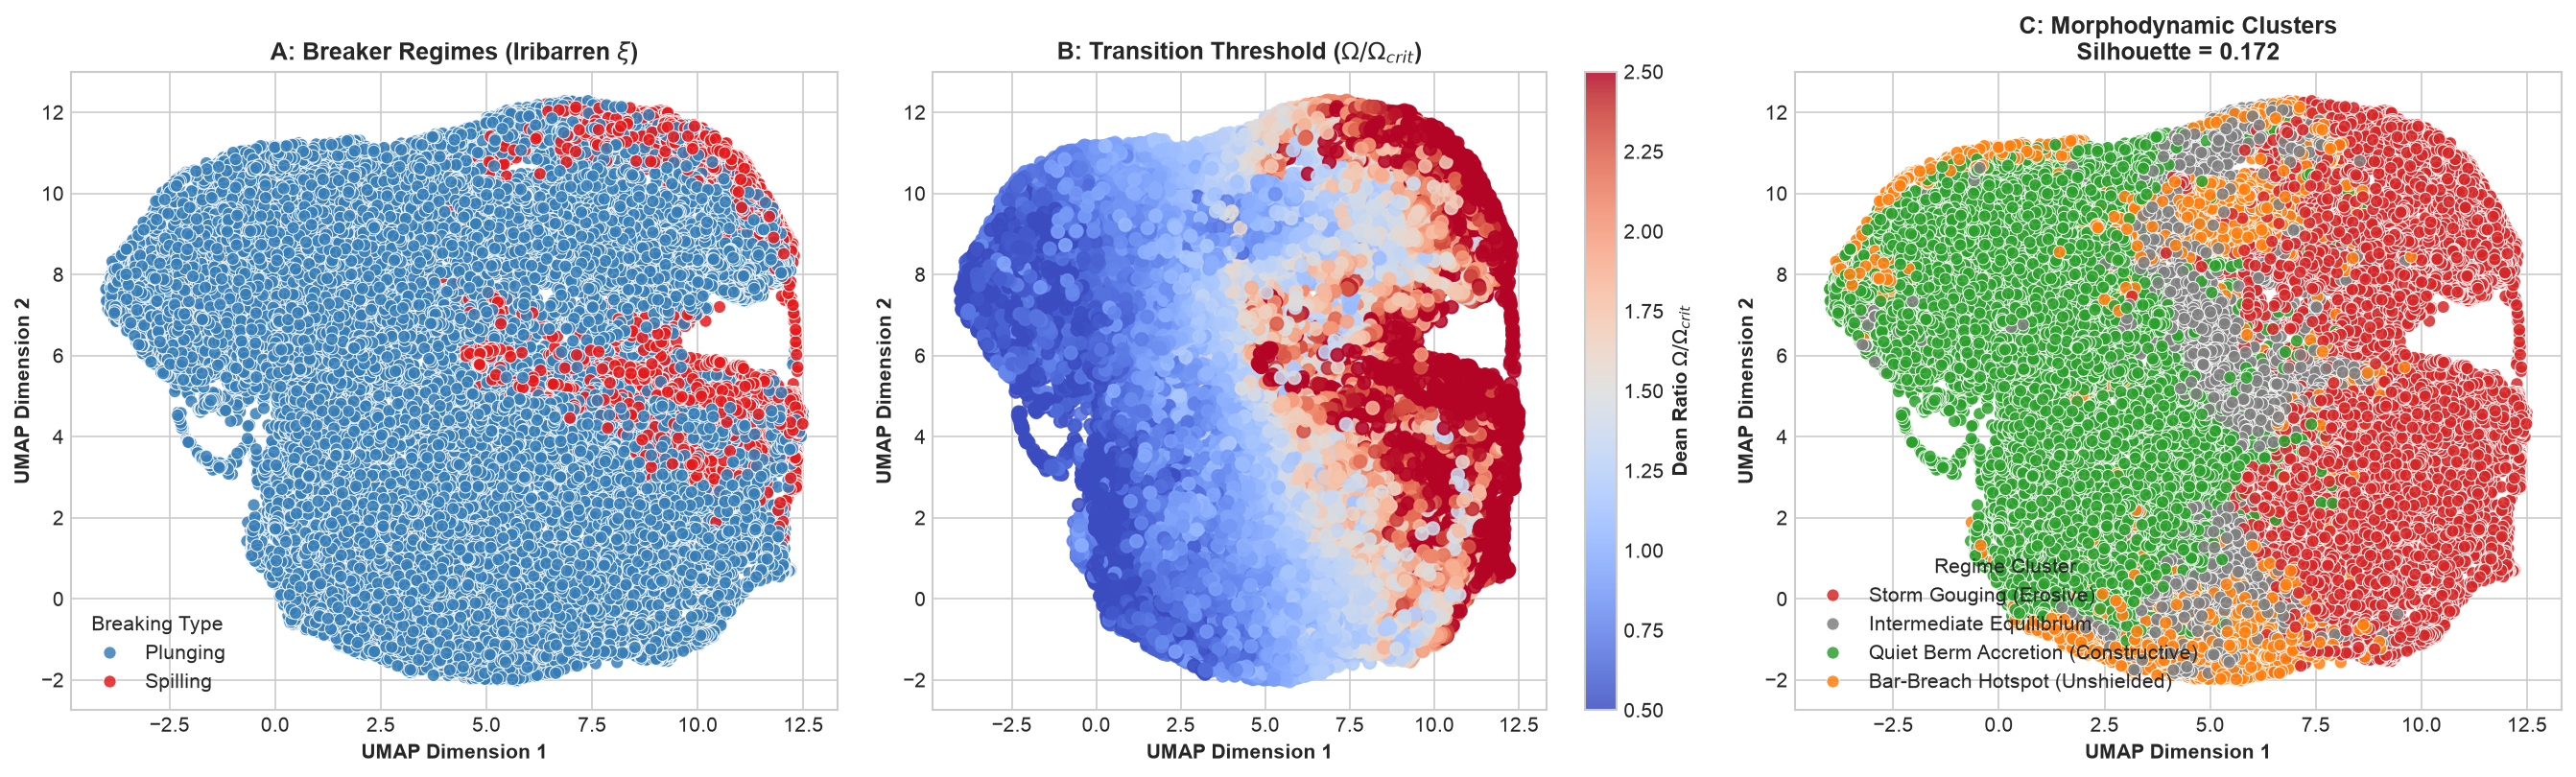

In [12]:
# 1. Compute data-driven embeddings and regime classification
embeddings, feature_names = compute_latent_embeddings(
    df=df,
    site=SITE,                              # Coastal site profile key for site geomorphology
    normalize=True,                         # Robust z-score standardization of latent dimensions
)
print(f'Constructed {embeddings.shape[0]} state embedding vectors across {len(feature_names)} latent dimensions:')
print(', '.join(feature_names))

df_regimes = classify_morphodynamic_regimes(df)
df_projected = project_embeddings_umap(embeddings, random_state=42)
df_projected['breaker_regime'] = df['breaker_regime'].values
df_projected['morph_regime'] = df_regimes['morph_regime'].values

df['umap_dim1'] = df_projected[:, 0]
df['umap_dim2'] = df_projected[:, 1]
df['morphodynamic_regime'] = df_regimes['morph_regime'].values
df['omega_ratio'] = df_regimes[1] if isinstance(df_regimes, tuple) else (df['dean_number'].values / 1.75)

sil_score = evaluate_breaker_regime_clustering(embeddings, df['breaker_regime'])
print(f'Morphodynamic Regime Separation Silhouette Score: {float(sil_score):.4f}')

# 2. Multi-Panel 2D Manifold Cluster Visualizations
sil_morph = evaluate_breaker_regime_clustering(df_projected, df['morphodynamic_regime'].values)
sil_val = float(sil_morph['silhouette_score'])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Breaker Regime Clusters
palette_brk = {'Spilling': '#e41a1c', 'Plunging': '#377eb8', 'Surging': '#4daf4a', 'Surging / Collapsing': '#4daf4a'}
sns.scatterplot(data=df, x='umap_dim1', y='umap_dim2', hue='breaker_regime', palette=palette_brk, s=40, alpha=0.85, ax=ax1)
ax1.set_title(r'A: Breaker Regimes (Iribarren $\xi$)', fontweight='bold')
ax1.set_xlabel('UMAP Dimension 1', fontweight='bold')
ax1.set_ylabel('UMAP Dimension 2', fontweight='bold')
ax1.legend(title='Breaking Type', framealpha=0.9)

# Panel 2: Normalized Dean Ratio Omega / Omega_crit
sc2 = ax2.scatter(df['umap_dim1'], df['umap_dim2'], c=df['omega_ratio'], cmap='coolwarm', s=40, alpha=0.85, vmin=0.5, vmax=2.5)
cbar2 = plt.colorbar(sc2, ax=ax2)
cbar2.set_label(r'Dean Ratio $\Omega / \Omega_{crit}$', fontweight='bold')
ax2.set_title(r'B: Transition Threshold ($\Omega / \Omega_{crit}$)', fontweight='bold')
ax2.set_xlabel('UMAP Dimension 1', fontweight='bold')
ax2.set_ylabel('UMAP Dimension 2', fontweight='bold')

# Panel 3: Morphodynamic Regimes
palette_morph = {'Storm Gouging (Erosive)': '#d62728', 'Quiet Berm Accretion (Constructive)': '#2ca02c', 'Bar-Breach Hotspot (Unshielded)': '#ff7f0e', 'Intermediate Equilibrium': '#7f7f7f'}
sns.scatterplot(data=df, x='umap_dim1', y='umap_dim2', hue='morphodynamic_regime', palette=palette_morph, s=40, alpha=0.85, ax=ax3)
ax3.set_title(f'C: Morphodynamic Clusters\nSilhouette = {sil_val:.3f}', fontweight='bold')
ax3.set_xlabel('UMAP Dimension 1', fontweight='bold')
ax3.set_ylabel('UMAP Dimension 2', fontweight='bold')
ax3.legend(title='Regime Cluster', framealpha=0.9)

plt.tight_layout()
plt.show()


## Section 7: Hierarchical Parent-Child Physics-RAG with DuckDB & Gemini Flash

An enterprise-grade, embedded **Hierarchical Parent-Child Physics-RAG** architecture enabling natural language querying across instantaneous physical states while automatically hydrating continuous multi-channel time-series context windows (±72h) via DuckDB SQL and Apache Parquet.

### Architectural Blueprint:
1. **Child Vector Search Layer**: Instantaneous discrete hydrodynamic states ($H_s, T_p, S, W_a, \xi, \Upsilon, \Omega, \Delta P_{\text{dissip}}$) indexed in-memory using Scikit-Learn `NearestNeighbors(metric="cosine")` with structured physical regime & noise filtering.
2. **Local Columnar Parent Storage (DuckDB + Parquet)**: High-frequency continuous multi-channel sensor sequences saved to `data/duck_sensors.parquet` and queried via embedded DuckDB SQL.
3. **Temporal Context Hydration (±72h Windows)**: When a child event matches (e.g. peak storm surge), DuckDB SQL slices the surrounding temporal window (`event_time - INTERVAL 72 HOUR` to `event_time + INTERVAL 24 HOUR`) to compute antecedent wave rise rate, cumulative wave power impulse $\int P_{\text{flux}} dt$, coincident surge duration, and net shoreline displacement $\Delta X_{\text{net}}$.
4. **Multi-Scale Narrative Synthesis (Gemini Flash)**: Gemini Flash combines instantaneous child parameters with hydrated parent time-series evolution to generate grounded physical root-cause diagnostics.

In [13]:
# Initialize Hierarchical Parent-Child Physics-RAG engine with DuckDB & Parquet
rag = HierarchicalPhysicsRAG(
    df=df,
    parquet_path="data/duck_sensors.parquet", # Local columnar parent sequence storage
    latent_embeddings=embeddings,             # 14-D physics latent vector matrix
    feature_names=feature_names,              # Feature dimension name list
    top_k=5,                                  # Default retrieval nearest-neighbor count
    default_pre_window_hours=72.0,            # Antecedent context window (-72h)
    default_post_window_hours=24.0,           # Post-event context window (+24h)
    model_name="gemini-2.5-flash",            # Gemini model identifier for query parser
    similarity_metric="cosine",               # Distance metric: 'cosine', 'euclidean'
)

# Export parent sequences to local Parquet file for high-performance DuckDB querying
os.makedirs("data", exist_ok=True)
rag.export_parent_parquet("data/duck_sensors.parquet")

print('=' * 85)
print('PART A: Core Physical Regime & Semantic Vector Queries')
print('=' * 85)

# Baseline Query 1: Spilling Breakers
res_spill = rag.query('Show me all the Spilling breakers', top_k=3)
print('\n[Query 1: Breaker Regime] "Show me all the Spilling breakers"')
print(res_spill.summary())
print('-' * 85)

# Baseline Query 2: Hurricane Ian Storm Peak & Beach Cut
res_ian = rag.query('Find high energy storm waves over 3m during Hurricane Ian with severe beach cut', top_k=3, pre_window_hours=72, post_window_hours=48)
print('\n[Query 2: Storm Peak & Cut] "Find high energy storm waves over 3m during Hurricane Ian with severe beach cut"')
print(res_ian.summary())
print('-' * 85)

# Baseline Query 3: Calm Fair Weather Accretion
res_calm = rag.query('Show calm summer accretion conditions with long period swell', top_k=3, pre_window_hours=72, post_window_hours=72)
print('\n[Query 3: Calm Accretion] "Show calm summer accretion conditions with long period swell"')
print(res_calm.summary())
print('-' * 85)

# Baseline Query 4: Synthetic Target Projection
res_synth = rag.query('Retrieve states with plunging breakers and strong onshore winds above 10 m/s', top_k=3)
print('\n[Query 4: Synthetic Projection] "Retrieve states with plunging breakers and strong onshore winds above 10 m/s"')
print(res_synth.summary())

print('\n' + '=' * 85)
print('PART B: Hierarchical Parent-Child Temporal Metrics (Metrics 1-5 with DuckDB Hydration)')
print('=' * 85)

# Temporal Metric 1: Antecedent Wave Energy Buildup & Storm Intensification
res_buildup = rag.query(
    'Find severe storm events with fast antecedent wave height rise rate',
    top_k=3,
    pre_window_hours=72,
    post_window_hours=24,
)
print('\n[Metric 1 - Antecedent Rise Rate] "Find severe storm events with fast antecedent wave height rise rate"')
print(res_buildup.summary())
print('-' * 85)

# Temporal Metric 2: Cumulative Wave Energy Impulse during Extreme Storm
res_impulse = rag.query(
    'Find severe storm events with high cumulative wave energy flux impulse during Hurricane Ian',
    top_k=3,
    pre_window_hours=72,
    post_window_hours=48,
)
print('\n[Metric 2 - Cumulative Wave Energy Impulse] "Find severe storm events with high cumulative wave energy flux impulse during Hurricane Ian"')
print(res_impulse.summary())
print('-' * 85)

# Temporal Metric 3: Coincident Storm Surge Duration & Total Water Level
res_surge_dur = rag.query(
    'Find storm surge events with prolonged surge elevation above 0.5m',
    top_k=3,
    pre_window_hours=48,
    post_window_hours=24,
)
print('\n[Metric 3 - Coincident Surge Duration] "Find storm surge events with prolonged surge elevation above 0.5m"')
print(res_surge_dur.summary())
print('-' * 85)

# Temporal Metric 4: Net Morphodynamic Shoreline Cut & Event-Scale Recession
res_net_cut = rag.query(
    'Find severe beach cut events with net shoreline recession over -1m across parent window',
    top_k=3,
    pre_window_hours=72,
    post_window_hours=24,
)
print('\n[Metric 4 - Net Shoreline Displacement] "Find severe beach cut events with net shoreline recession over -1m across parent window"')
print(res_net_cut.summary())
print('-' * 85)

# Temporal Metric 5: Signed Disequilibrium & Post-Storm Berm Accretion Trajectory
res_recovery_phase = rag.query(
    'Find post-storm beach recovery phases driven by negative Signed Disequilibrium and swash berm welding',
    top_k=3,
    pre_window_hours=72,
    post_window_hours=72,
)
print('\n[Metric 5 - Recovery & Disequilibrium Trajectory] "Find post-storm beach recovery phases driven by negative Signed Disequilibrium and swash berm welding"')
print(res_recovery_phase.summary())

PART A: Core Physical Regime & Semantic Vector Queries


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.



[Query 1: Breaker Regime] "Show me all the Spilling breakers"
=== Hierarchical Parent-Child Physics-RAG Results ===
Query: "Show me all the Spilling breakers"
Child Event Matches (Top-k): 3
Hydrated Parent Windows: 3

Multi-Scale Physical Diagnostic Narrative:
This hierarchical search query for "Spilling breakers" has effectively identified instantaneous hydrodynamic states characterized by this specific breaker regime and, crucially, provided the antecedent and subsequent multi-channel temporal evolution via the hydrated parent time-series. This multi-scale approach is invaluable for understanding the drivers and consequences of coastal processes.

### Overall Assessment of Spilling Breaker Events

The three top child vector matches consistently identify conditions conducive to spilling breakers, characterized by Iribarren numbers (ξ_iribarren) ranging from 0.393 to 0.403. These values are well within the typical range for spilling breakers on gently sloping beaches, where wave energ

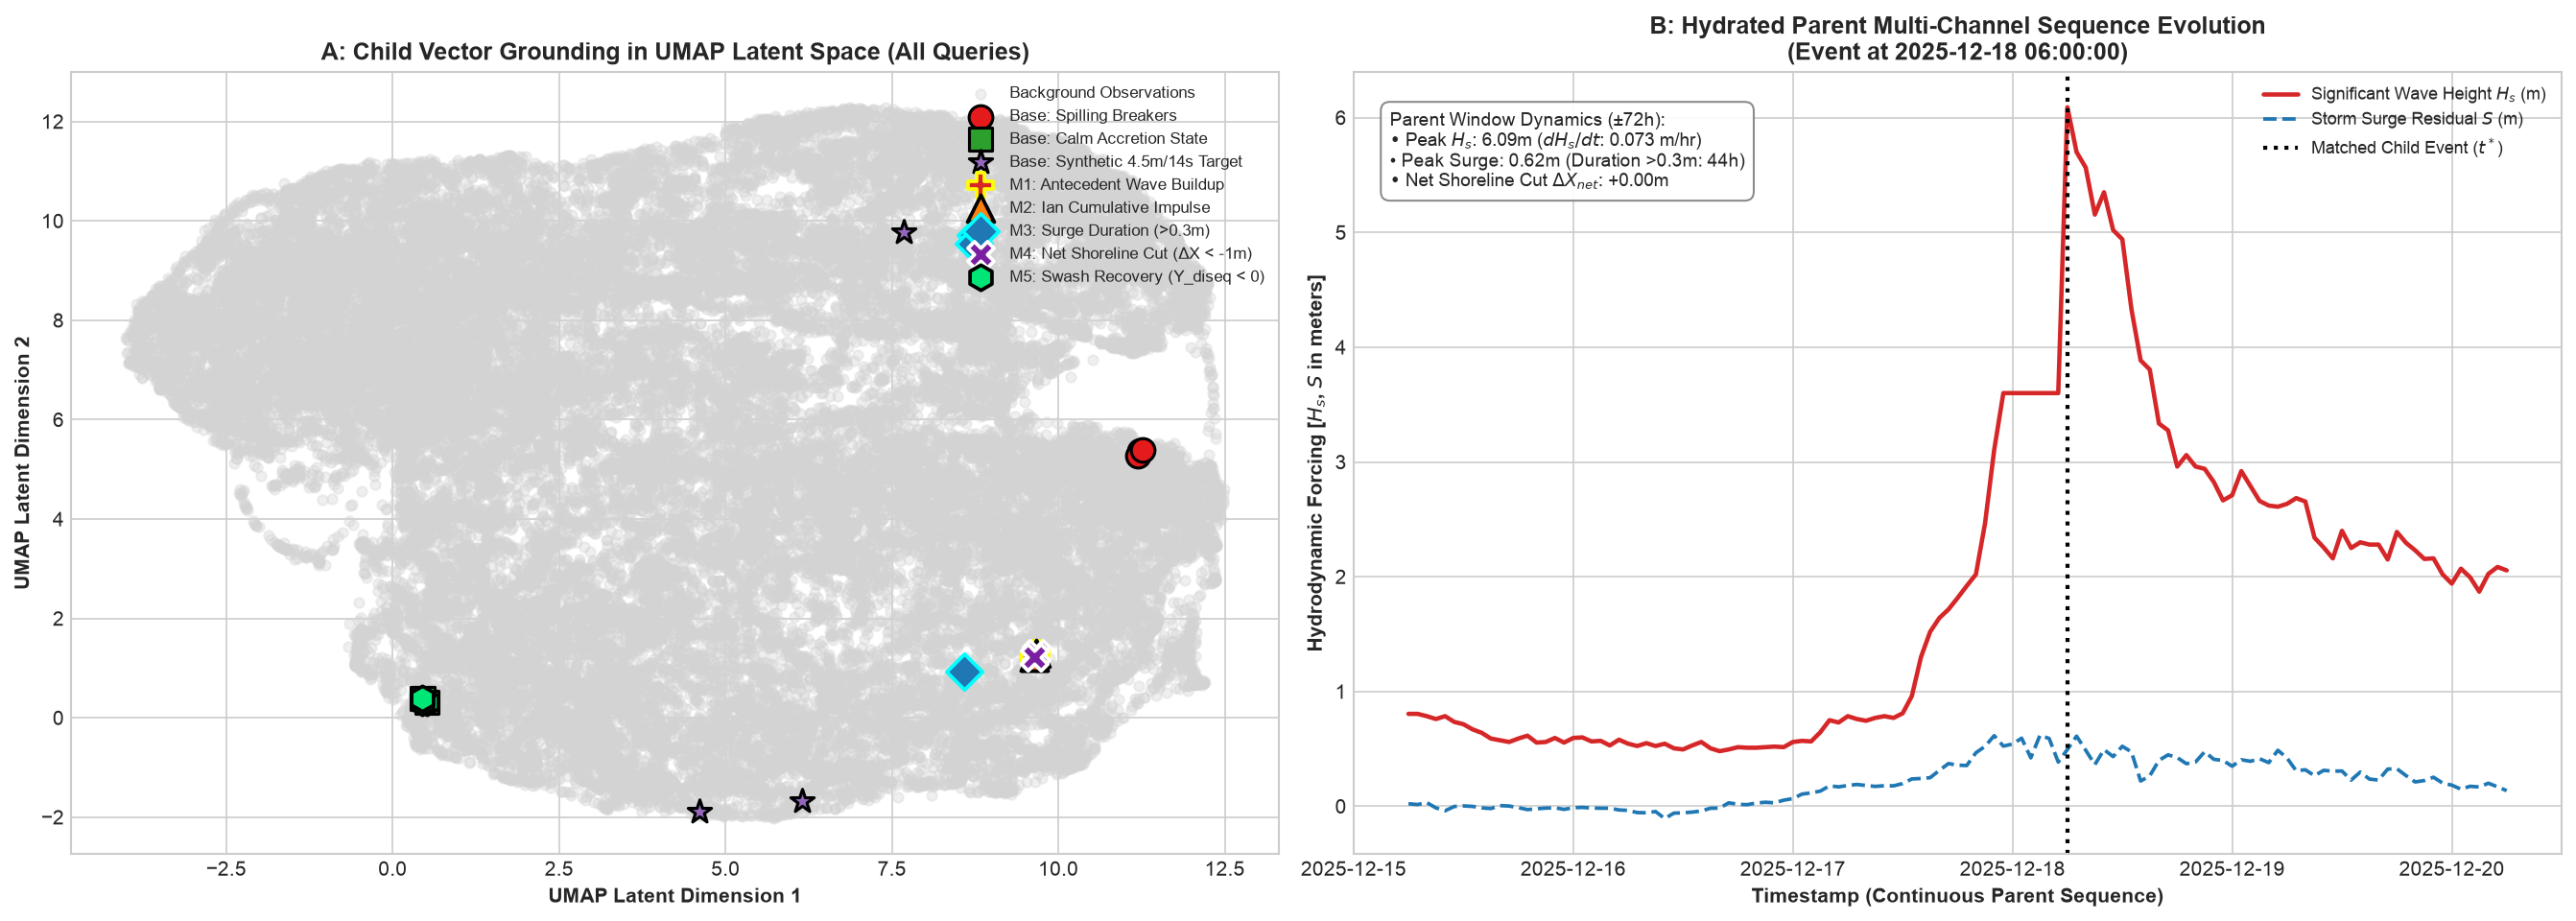

In [14]:
# Multi-Scale Visualization of Hierarchical Parent-Child Physics-RAG
fig, (ax_umap, ax_ts) = plt.subplots(1, 2, figsize=(18, 6.5))

# -------------------------------------------------------------------------
# Panel 1: UMAP Latent Space Grounding (Baseline Regimes + Temporal Metrics)
# -------------------------------------------------------------------------
ax_umap.scatter(df['umap_dim1'], df['umap_dim2'], c='lightgray', s=25, alpha=0.35, label='Background Observations')

# Baseline queries
if not res_spill.child_matches_df.empty:
    ax_umap.scatter(res_spill.child_matches_df['umap_dim1'], res_spill.child_matches_df['umap_dim2'],
                    color='#e41a1c', s=140, edgecolors='black', lw=1.5, marker='o', zorder=4,
                    label='Base: Spilling Breakers')

if not res_calm.child_matches_df.empty:
    ax_umap.scatter(res_calm.child_matches_df['umap_dim1'], res_calm.child_matches_df['umap_dim2'],
                    color='#2ca02c', s=140, edgecolors='black', lw=1.5, marker='s', zorder=4,
                    label='Base: Calm Accretion State')

if not res_synth.child_matches_df.empty:
    ax_umap.scatter(res_synth.child_matches_df['umap_dim1'], res_synth.child_matches_df['umap_dim2'],
                    color='#9467bd', s=150, edgecolors='black', lw=1.5, marker='*', zorder=4,
                    label='Base: Synthetic 4.5m/14s Target')

# Temporal Parent-Child queries
if not res_buildup.child_matches_df.empty:
    ax_umap.scatter(res_buildup.child_matches_df['umap_dim1'], res_buildup.child_matches_df['umap_dim2'],
                    color='#d62728', s=160, edgecolors='yellow', lw=1.8, marker='P', zorder=5,
                    label='M1: Antecedent Wave Buildup')

if not res_impulse.child_matches_df.empty:
    ax_umap.scatter(res_impulse.child_matches_df['umap_dim1'], res_impulse.child_matches_df['umap_dim2'],
                    color='#ff7f0e', s=180, edgecolors='black', lw=1.8, marker='^', zorder=5,
                    label='M2: Ian Cumulative Impulse')

if not res_surge_dur.child_matches_df.empty:
    ax_umap.scatter(res_surge_dur.child_matches_df['umap_dim1'], res_surge_dur.child_matches_df['umap_dim2'],
                    color='#1f77b4', s=160, edgecolors='cyan', lw=1.8, marker='D', zorder=5,
                    label='M3: Surge Duration (>0.3m)')

if not res_net_cut.child_matches_df.empty:
    ax_umap.scatter(res_net_cut.child_matches_df['umap_dim1'], res_net_cut.child_matches_df['umap_dim2'],
                    color='#7b1fa2', s=170, edgecolors='white', lw=1.8, marker='X', zorder=5,
                    label='M4: Net Shoreline Cut (ΔX < -1m)')

if not res_recovery_phase.child_matches_df.empty:
    ax_umap.scatter(res_recovery_phase.child_matches_df['umap_dim1'], res_recovery_phase.child_matches_df['umap_dim2'],
                    color='#00e676', s=160, edgecolors='black', lw=1.8, marker='h', zorder=5,
                    label='M5: Swash Recovery (Υ_diseq < 0)')

ax_umap.set_title('A: Child Vector Grounding in UMAP Latent Space (All Queries)', fontweight='bold', fontsize=12)
ax_umap.set_xlabel('UMAP Latent Dimension 1', fontweight='bold')
ax_umap.set_ylabel('UMAP Latent Dimension 2', fontweight='bold')
ax_umap.legend(framealpha=0.95, loc='upper right', fontsize=8.0)

# -------------------------------------------------------------------------
# Panel 2: Hydrated Continuous Parent Time-Series Evolution (±72h Context Window via DuckDB)
# -------------------------------------------------------------------------
top_pw = res_impulse.parent_windows[0] if (res_impulse.parent_windows and res_impulse.parent_windows[0].parent_df is not None and not res_impulse.parent_windows[0].parent_df.empty) else res_ian.parent_windows[0]
parent_df = top_pw.parent_df

if parent_df is not None and not parent_df.empty:
    ts_time = pd.to_datetime(parent_df['timestamp'])
    event_time = pd.to_datetime(top_pw.event_timestamp)
    
    # Left axis: Wave height and storm surge
    color_hs = '#d62728'
    color_surge = '#1f77b4'
    color_dx = '#2ca02c'
    
    ax_ts.plot(ts_time, parent_df['hs_m'], color=color_hs, lw=2.2, label=r'Significant Wave Height $H_s$ (m)')
    if 'surge_m' in parent_df.columns:
        ax_ts.plot(ts_time, parent_df['surge_m'], color=color_surge, lw=1.8, linestyle='--', label=r'Storm Surge Residual $S$ (m)')
    
    ax_ts.axvline(event_time, color='black', lw=2.0, linestyle=':', label=f'Matched Child Event ($t^*$)')
    ax_ts.set_ylabel(r'Hydrodynamic Forcing [$H_s$, $S$ in meters]', fontweight='bold')
    ax_ts.set_xlabel('Timestamp (Continuous Parent Sequence)', fontweight='bold')
    
    # Right axis: Morphodynamic Shoreline Displacement
    if 'delta_x_m' in parent_df.columns:
        ax_ts_r = ax_ts.twinx()
        ax_ts_r.plot(ts_time, parent_df['delta_x_m'], color=color_dx, lw=2.0, linestyle='-.', label=r'Shoreline Position $\Delta X$ (m)')
        ax_ts_r.set_ylabel(r'Shoreline Displacement $\Delta X$ (m)', color=color_dx, fontweight='bold')
        ax_ts_r.tick_params(axis='y', labelcolor=color_dx)
        ax_ts_r.grid(False)
    
    st = top_pw.summary_stats
    stats_text = (
        f"Parent Window Dynamics (±72h):\n"
        f"• Peak $H_s$: {st.get('peak_hs_m', 0.0):.2f}m ($dH_s/dt$: {st.get('hs_rise_rate_m_per_hr', 0.0):.3f} m/hr)\n"
        f"• Peak Surge: {st.get('peak_surge_m', 0.0):.2f}m (Duration >0.3m: {st.get('surge_duration_hours', 0.0):.0f}h)\n"
        f"• Net Shoreline Cut $\Delta X_{{net}}$: {st.get('net_delta_x_m', 0.0):+.2f}m"
    )
    ax_ts.text(0.03, 0.95, stats_text, transform=ax_ts.transAxes, verticalalignment='top',
               fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='gray'))
    
    ax_ts.set_title(f'B: Hydrated Parent Multi-Channel Sequence Evolution\n(Event at {top_pw.event_timestamp})', fontweight='bold', fontsize=12)
    ax_ts.legend(loc='upper right', fontsize=8.5, framealpha=0.95)

plt.tight_layout()
plt.show()

### Quantitative Physics-RAG Retrieval Benchmark (Precision@k, Regime Purity, MRR)

We quantitatively evaluate retrieval accuracy, physical regime purity, mean reciprocal rank (MRR), and recall across 10 canonical oceanographic query categories spanning wave breaking regimes, extreme storms, and morphodynamic states.

In [15]:
# Execute Quantitative Physics-RAG Retrieval Benchmark Suite
print("Evaluating Quantitative Physics-RAG Retrieval Benchmark across k in [1, 3, 5, 10]...")
df_rag_bench, macro_summary = evaluate_rag_benchmark_suite(
    rag_engine=rag,
    k_values=[1, 3, 5, 10],                 # Evaluation precision cutoff ranks
    # verbose=False,                          # Verbose query-by-query output logging
)

print()
print("=== PHYSICS-RAG RETRIEVAL ACCURACY & REGIME PURITY BENCHMARK ===")
print(tabulate(df_rag_bench, headers="keys", tablefmt="fancy_grid", floatfmt=".3f"))

print()
print("=== MACRO-AVERAGED RETRIEVAL BENCHMARK SUMMARY ===")
for metric_name, metric_val in macro_summary.items():
    print(f"{metric_name:30s}: {metric_val:.4f}")


Evaluating Quantitative Physics-RAG Retrieval Benchmark across k in [1, 3, 5, 10]...

=== PHYSICS-RAG RETRIEVAL ACCURACY & REGIME PURITY BENCHMARK ===
╒════╤══════════════════════════════════════════════════════════════════════════════╤════════════════════════════════════╤═════════════════╤═══════╤═══════╤═══════╤═══════════════════╤═══════╤════════════╤══════════════╤═══════════════════╤════════╕
│    │ Query                                                                        │ Category                           │ Target Regime   │   P@1 │   P@3 │   P@5 │   Regime Purity@5 │   MRR │   Recall@5 │   Mean Sim@5 │   Dataset Support │   P@10 │
╞════╪══════════════════════════════════════════════════════════════════════════════╪════════════════════════════════════╪═════════════════╪═══════╪═══════╪═══════╪═══════════════════╪═══════╪════════════╪══════════════╪═══════════════════╪════════╡
│  0 │ Show me all the Spilling breakers                                            │ Breaker Regim

## Section 8: Multi-Site Partitioned Parent Storage, Metadata Pre-Filtering & Universal Latent Space Projection

To scale the Physics-RAG architecture globally across diverse coastal geomorphic regimes without sacrificing retrieval speed or spatial context, we **unify the Child Vector Search Layer** across all 5 canonical research sites while **partitioning the Parent Context Storage Layer** by geographic location (`data/{site}_sensors.parquet`).

### Key Architectural & Oceanographic Innovations

1. **Unified Child Vector Store with Dynamic Metadata Tagging**:
   - Each child vector is indexed with metadata tags: `site_id` (`duck_nc`, `narrabeen_aus`, `oahu_north_shore_hi`, `torrey_pines_ca`, `truc_vert_france`) and `geomorphic_regime` (`microtidal`, `embayed`, `reef`, `narrow_shelf`, `macrotidal`).
   - When a query like *"Find extreme wave dissipation events at macrotidal sites"* is submitted, Gemini Flash / `PhysicsQueryParser` extracts `geomorphic_regime = "macrotidal"` (or `site_id = "truc_vert_france"`), naturally restricting vector search to Truc Vert candidates **before** computing cosine distance similarity.

2. **Partitioned Parent Context Layer (`data/{site}_sensors.parquet`) & DuckDB SQL Routing**:
   - Parent sensor time-series sequences are saved in location-partitioned Parquet files (`data/duck_nc_sensors.parquet`, `data/truc_vert_france_sensors.parquet`, etc.).
   - Upon matching a child vector event, DuckDB routes the SQL query directly to `data/{site}_sensors.parquet` to hydrate the exact $\pm 72$-hour antecedent sequence—pulling wave height rise rate (m/h), cumulative wave power impulse (MJ/m), and coincident storm surge duration for that specific geographic event.

3. **5-Site Universal Latent Space Projection (UMAP)**:
   - By projecting all five global sites into a single joint UMAP latent space embedding, we demonstrate that the **Unified Coastal Vulnerability Index ($\Upsilon$)** clusters equivalent physical states regardless of geography.
   - A Hawaiian winter groundswell (`oahu_north_shore_hi`) and a North Carolina hurricane (`duck_nc`) occupy the exact same "storm gouging" neighborhood in latent space because they represent equivalent hydrodynamic work ($\Upsilon$), completely transcending their distinct meteorological climates.


In [ ]:
# 1. Ingest multi-site continuous datasets across 5 canonical global research sites
from src.data import fetch_site_annual_dataset
from src.physics_rag import HierarchicalPhysicsRAG
from tabulate import tabulate

SITE_REGIME_MAP = {
    "duck_nc": "microtidal",
    "narrabeen_aus": "embayed",
    "oahu_north_shore_hi": "reef",
    "torrey_pines_ca": "narrow_shelf",
    "truc_vert_france": "macrotidal",
}

print("Ingesting multi-site continuous datasets and building partitioned parent storage (data/{site}_sensors.parquet)...")
dfs_multisite = []
for s_key, regime in SITE_REGIME_MAP.items():
    df_s = fetch_site_annual_dataset(site=s_key, year=2022, morph_model="xbeach", try_live_api=False)
    df_s["site"] = s_key
    df_s["geomorphic_regime"] = regime
    dfs_multisite.append(df_s)

df_global = pd.concat(dfs_multisite, axis=0).reset_index(names="timestamp")
print(f"Global Multi-Site Dataset constructed: N = {len(df_global):,} hourly vectors across {len(SITE_REGIME_MAP)} global sites.")

# Construct Unified Hierarchical Physics-RAG Engine across all 5 sites
rag_global = HierarchicalPhysicsRAG.from_dataset(df_global, model_name="gemini-2.5-flash")

# Export partitioned Parquet storage per site for DuckDB SQL routing
partition_files = rag_global.export_partitioned_parent_parquet(output_dir="data")
print("\nExported Partitioned Parent Parquet Storage files:")
for s_name, p_path in partition_files.items():
    print(f"  • {s_name:20s} -> {p_path}")


In [ ]:
# 2. Dynamic Pre-Filtered Query: "Find extreme wave dissipation events at macrotidal sites"
query_macrotidal = "Find extreme wave dissipation events at macrotidal sites"
print(f"Executing Pre-Filtered Physics-RAG Query: {query_macrotidal}\n")

res_macro = rag_global.query(query_macrotidal, top_k=3, pre_window_hours=72, post_window_hours=24)

print(f"Parsed Criteria Site/Regime: site_id = {res_macro.parsed_criteria.site_id}, regime = {res_macro.parsed_criteria.geomorphic_regime}")
print(f"Matched Child Vector Sites: {res_macro.child_matches_df[site].tolist()}")
print("\nTop Matched Child Events:")
show_cols_global = [c for c in ["timestamp", "site", "geomorphic_regime", "hs_m", "tp_s", "surge_m", "upsilon", "similarity"] if c in res_macro.child_matches_df.columns]
print(tabulate(res_macro.child_matches_df[show_cols_global], headers="keys", tablefmt="fancy_grid", floatfmt=".4f"))

# Inspect hydrated parent window from Truc Vert partitioned parquet file via DuckDB
if len(res_macro.parent_windows) > 0:
    pw_top = res_macro.parent_windows[0]
    print("\nParent Window Context Hydrated via DuckDB Site Routing:")
    print(f"  • Event Timestamp: {pw_top.event_timestamp}")
    print(f"  • Sequence Length: {len(pw_top.parent_df)} hours (-72h to +24h)")
    for k, v in pw_top.summary_stats.items():
        print(f"  • {k}: {v:.4f}" if isinstance(v, float) else f"  • {k}: {v}")


In [ ]:
# 3. Publication-Quality Universal Latent Space Projection (5-Site Joint UMAP Embedding)
from src.embeddings import build_physics_anchored_feature_matrix, project_embeddings_umap
from sklearn.preprocessing import RobustScaler

print("Computing Joint High-Dimensional Physics Embeddings across 5 Global Sites...")
X_global, f_names_global = build_physics_anchored_feature_matrix(df_global)
scaler_global = RobustScaler()
X_norm_global = scaler_global.fit_transform(X_global)

# Subsample vectors evenly for crisp publication visualization if dataset is large
sub_indices = np.random.choice(len(df_global), size=min(12000, len(df_global)), replace=False)
df_sub = df_global.iloc[sub_indices].copy().reset_index(drop=True)
X_sub = X_norm_global[sub_indices]

umap_res = project_embeddings_umap(X_sub, n_neighbors=30, min_dist=0.25, metric="cosine", random_state=42)
coords_global = np.asarray(umap_res)
df_sub["umap_1"] = coords_global[:, 0]
df_sub["umap_2"] = coords_global[:, 1]

# Plot Universal Latent Space Projection
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8.5), layout="constrained")

site_palette = {
    "duck_nc": "#1f77b4",          # Atlantic Blue
    "narrabeen_aus": "#ff7f0e",     # Coral Orange
    "oahu_north_shore_hi": "#2ca02c",# Pacific Green
    "torrey_pines_ca": "#9467bd",   # Purple
    "truc_vert_france": "#d62728",  # Biscay Red
}

site_markers = {
    "duck_nc": "o",
    "narrabeen_aus": "s",
    "oahu_north_shore_hi": "^",
    "torrey_pines_ca": "D",
    "truc_vert_france": "X",
}

# Left Panel: 5-Site Geographic Provenance Overlay
for s_key, s_df in df_sub.groupby("site"):
    s_label = s_key.upper().replace("_", " ")
    ax1.scatter(
        s_df["umap_1"],
        s_df["umap_2"],
        c=site_palette.get(s_key, "#333333"),
        marker=site_markers.get(s_key, "o"),
        label=s_label,
        alpha=0.60,
        s=28,
        edgecolors="none",
    )

ax1.set_title("A. Universal Latent Space: 5-Site Geographic Provenance Projection", fontweight="bold", fontsize=13)
ax1.set_xlabel("UMAP Dimension 1 (Hydrodynamic Forcing)", fontweight="bold", fontsize=11)
ax1.set_ylabel("UMAP Dimension 2 (Morphodynamic Dissipation)", fontweight="bold", fontsize=11)
ax1.legend(loc="upper right", framealpha=0.95, fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.5)

# Right Panel: Universal Vulnerability Index (Upsilon) Continuous Clustering
scatter = ax2.scatter(
    df_sub["umap_1"],
    df_sub["umap_2"],
    c=df_sub["log_upsilon"],
    cmap="plasma",
    alpha=0.75,
    s=30,
    edgecolors="none",
)
cbar = fig.colorbar(scatter, ax=ax2, pad=0.02)
cbar.set_label(r"Log Unified Coastal Vulnerability Index $\log_{10}(\Upsilon)$", fontweight="bold", fontsize=11)

# Annotate equivalent physical state clusters across Hawaiian swell vs. Atlantic storm
hawaii_peak = df_sub[df_sub["site"] == "oahu_north_shore_hi"]["log_upsilon"].idxmax()
duck_peak = df_sub[df_sub["site"] == "duck_nc"]["log_upsilon"].idxmax()

ax2.annotate(
    "Hawaiian Giant Swell\n(Oahu Peak Forcing)",
    (df_sub.loc[hawaii_peak, "umap_1"], df_sub.loc[hawaii_peak, "umap_2"]),
    xytext=(-60, 40),
    textcoords="offset points",
    fontweight="bold",
    fontsize=9.5,
    color="#000000",
    bbox=dict(boxstyle="round,pad=0.3", fc="#ffffff", ec="#2ca02c", lw=1.5),
    arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.8),
)

ax2.annotate(
    "Hurricane Landfall\n(Duck NC Peak Gouging)",
    (df_sub.loc[duck_peak, "umap_1"], df_sub.loc[duck_peak, "umap_2"]),
    xytext=(20, -50),
    textcoords="offset points",
    fontweight="bold",
    fontsize=9.5,
    color="#000000",
    bbox=dict(boxstyle="round,pad=0.3", fc="#ffffff", ec="#1f77b4", lw=1.5),
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.8),
)

ax2.set_title(r"B. Universal State Clustering: Unified Index $\Upsilon$ Manifold Alignment", fontweight="bold", fontsize=13)
ax2.set_xlabel("UMAP Dimension 1 (Hydrodynamic Forcing)", fontweight="bold", fontsize=11)
ax2.set_ylabel("UMAP Dimension 2 (Morphodynamic Dissipation)", fontweight="bold", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.5)

plt.show()
